In [1]:

!pip install kagglehub
import kagglehub
path = kagglehub.dataset_download("shashwatwork/knee-osteoarthritis-dataset-with-severity")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'knee-osteoarthritis-dataset-with-severity' dataset.
Path to dataset files: /kaggle/input/knee-osteoarthritis-dataset-with-severity


In [2]:
!ls {path}

auto_test  test  train	val


In [3]:
from torchvision import transforms, datasets

base = path

tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)

print("train:", len(train), "| val:", len(val), "| test:", len(test))
print("classes:", train.classes)


train: 5778 | val: 826 | test: 1656
classes: ['0', '1', '2', '3', '4']


In [4]:
from collections import Counter

for name, ds in [("train", train), ("val", val), ("test", test)]:
    counts = Counter(ds.targets)
    print(name, {ds.classes[k]: v for k, v in sorted(counts.items())})


train {'0': 2286, '1': 1046, '2': 1516, '3': 757, '4': 173}
val {'0': 328, '1': 153, '2': 212, '3': 106, '4': 27}
test {'0': 639, '1': 296, '2': 447, '3': 223, '4': 51}


In [5]:
import torch

counts = Counter(train.targets)
total = sum(counts.values())
weights = [total / (5 * counts[i]) for i in range(5)]
class_weights = torch.tensor(weights, dtype=torch.float)

print("class weights:", [round(w, 2) for w in weights])


class weights: [0.51, 1.1, 0.76, 1.53, 6.68]


In [6]:
train_tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((224,224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=train_tf)
print("train:", len(train))


train: 5778


In [7]:
from torch.utils.data import DataLoader

val = datasets.ImageFolder(f"{base}/val", transform=tf)
test = datasets.ImageFolder(f"{base}/test", transform=tf)

train_loader = DataLoader(train, batch_size=32, shuffle=True)
val_loader = DataLoader(val, batch_size=32, shuffle=False)
test_loader = DataLoader(test, batch_size=32, shuffle=False)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("labels:", labels[:10])


batch shape: torch.Size([32, 3, 224, 224])
labels: tensor([2, 0, 1, 0, 0, 2, 2, 1, 1, 1])


In [8]:
import cv2
import numpy as np
from PIL import Image
from torch.utils.data import DataLoader

# 1) دالة التنظيف: noise reduction + تحسين التباين
class Denoise:
    def __call__(self, img):
        g = np.array(img.convert("L"))                      # رمادي
        g = cv2.GaussianBlur(g, (3, 3), 0)                  # إزالة الضوضاء
        g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)  # تحسين التباين
        return Image.fromarray(g)

# 2) pipeline للـ val و test (بدون augmentation)
tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 3) pipeline للـ train (مع augmentation)
train_tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 4) نعيد تحميل الداتا بالـ pipeline الجديد
train = datasets.ImageFolder(f"{base}/train", transform=train_tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)

train_loader = DataLoader(train, batch_size=32, shuffle=True)
val_loader   = DataLoader(val,   batch_size=32, shuffle=False)
test_loader  = DataLoader(test,  batch_size=32, shuffle=False)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("train:", len(train), "| val:", len(val), "| test:", len(test))


batch shape: torch.Size([32, 3, 224, 224])
train: 5778 | val: 826 | test: 1656


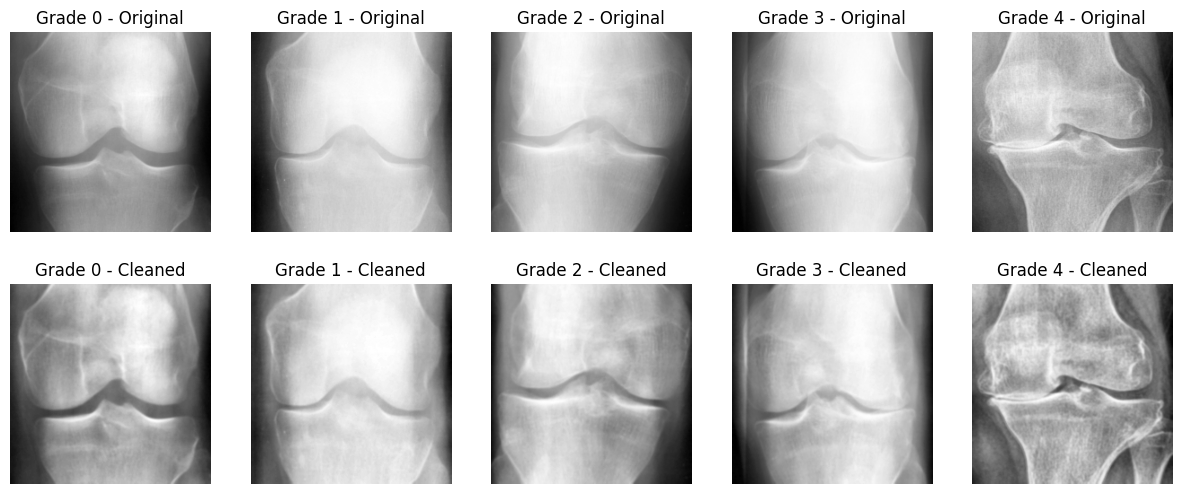

In [9]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for k in range(5):
    path_k = train.samples[train.targets.index(k)][0]
    original = Image.open(path_k).convert("L")
    cleaned = Denoise()(original)
    axes[0][k].imshow(original, cmap="gray"); axes[0][k].set_title(f"Grade {k} - Original"); axes[0][k].axis("off")
    axes[1][k].imshow(cleaned, cmap="gray"); axes[1][k].set_title(f"Grade {k} - Cleaned"); axes[1][k].axis("off")
plt.show()

# مو مهم بس عشان اشوف الصور قبل وبعد

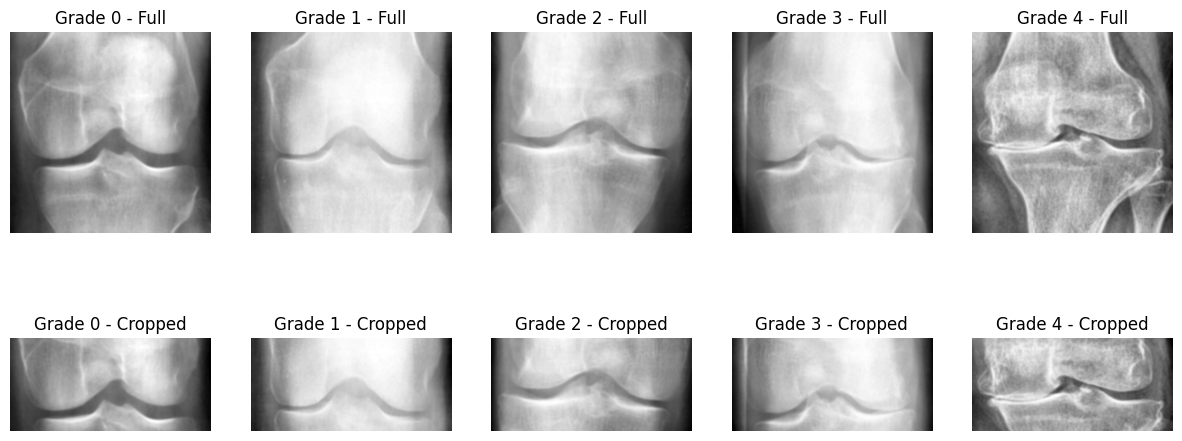

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

def crop_center(img, top=60, bottom=60):
    img = img.resize((224, 224))
    return img.crop((0, top, 224, 224 - bottom))   # 224 x 104

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for k in range(5):
    p = train.samples[train.targets.index(k)][0]
    original = Denoise()(Image.open(p).convert("L")).resize((224, 224))
    cropped = crop_center(Denoise()(Image.open(p).convert("L")))
    axes[0][k].imshow(original, cmap="gray"); axes[0][k].set_title(f"Grade {k} - Full"); axes[0][k].axis("off")
    axes[1][k].imshow(cropped, cmap="gray"); axes[1][k].set_title(f"Grade {k} - Cropped"); axes[1][k].axis("off")
plt.show()


In [ ]:

!pip install -q timm

import torch
import timm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load pretrained Xception for 5 KL grades
model = timm.create_model(
    "xception",
    pretrained=True,
    num_classes=5
)

model = model.to(device)

print("Device:", device)
print("Xception is ready!")


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
Device: cuda
Xception is ready!


In [ ]:

import torch.nn as nn
import torch.optim as optim

# Loss function with class weights
criterion = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

# Optimizer
optimizer = optim.Adam(
    model.parameters(),
    lr=0.0001
)

# Number of training epochs
num_epochs = 20

print("Loss function ready!")
print("Optimizer ready!")
print("Epochs:", num_epochs)


Loss function ready!
Optimizer ready!
Epochs: 20


In [ ]:

import torch
import copy
import time

best_val_acc = 0.0
best_model_weights = copy.deepcopy(model.state_dict())

history = {
    "train_loss": [],
    "train_acc": [],
    "val_loss": [],
    "val_acc": []
}

start_time = time.time()

for epoch in range(num_epochs):

    # TRAINING
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    epoch_train_loss = train_loss / train_total
    epoch_train_acc = 100 * train_correct / train_total

    # VALIDATION
    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_loss / val_total
    epoch_val_acc = 100 * val_correct / val_total

    history["train_loss"].append(epoch_train_loss)
    history["train_acc"].append(epoch_train_acc)
    history["val_loss"].append(epoch_val_loss)
    history["val_acc"].append(epoch_val_acc)

    print(
        f"Epoch {epoch+1}/{num_epochs} | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Acc: {epoch_train_acc:.2f}% | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Acc: {epoch_val_acc:.2f}%"
    )

    # Save best model based on validation accuracy
    if epoch_val_acc > best_val_acc:
        best_val_acc = epoch_val_acc
        best_model_weights = copy.deepcopy(model.state_dict())
        torch.save(
            best_model_weights,
            "/content/MUFSAL_Xception_best.pth"
        )
        print("Best model saved!")

print("\nTraining finished!")
print(f"Best Validation Accuracy: {best_val_acc:.2f}%")
print(f"Training time: {(time.time()-start_time)/60:.1f} minutes")

model.load_state_dict(best_model_weights)


Epoch 1/20 | Train Loss: 1.1904 | Train Acc: 43.51% | Val Loss: 1.0618 | Val Acc: 54.12%
Best model saved!
Epoch 2/20 | Train Loss: 0.8558 | Train Acc: 58.20% | Val Loss: 1.0389 | Val Acc: 49.76%
Epoch 3/20 | Train Loss: 0.7447 | Train Acc: 61.63% | Val Loss: 0.9898 | Val Acc: 57.87%
Best model saved!
Epoch 4/20 | Train Loss: 0.6670 | Train Acc: 66.16% | Val Loss: 0.9328 | Val Acc: 59.08%
Best model saved!
Epoch 5/20 | Train Loss: 0.5961 | Train Acc: 69.57% | Val Loss: 1.0703 | Val Acc: 52.66%
Epoch 6/20 | Train Loss: 0.5365 | Train Acc: 73.99% | Val Loss: 1.0507 | Val Acc: 56.17%
Epoch 7/20 | Train Loss: 0.4321 | Train Acc: 78.11% | Val Loss: 1.1149 | Val Acc: 57.63%
Epoch 8/20 | Train Loss: 0.3713 | Train Acc: 81.62% | Val Loss: 1.1891 | Val Acc: 56.90%
Epoch 9/20 | Train Loss: 0.3142 | Train Acc: 85.27% | Val Loss: 1.1991 | Val Acc: 61.50%
Best model saved!
Epoch 10/20 | Train Loss: 0.2676 | Train Acc: 86.95% | Val Loss: 1.4680 | Val Acc: 53.27%
Epoch 11/20 | Train Loss: 0.1967 | Tr

<All keys matched successfully>

In [ ]:

from google.colab import drive
import shutil

drive.mount('/content/drive')

shutil.copy(
    '/content/MUFSAL_Xception_best.pth',
    '/content/drive/MyDrive/MUFSAL_Xception_Exp1_best.pth'
)

print("Model saved successfully to Google Drive!")


Mounted at /content/drive
Model saved successfully to Google Drive!


              precision    recall  f1-score   support

     Grade 0       0.67      0.82      0.74       328
     Grade 1       0.40      0.12      0.18       153
     Grade 2       0.58      0.68      0.63       212
     Grade 3       0.78      0.73      0.75       106
     Grade 4       0.80      0.89      0.84        27

    accuracy                           0.65       826
   macro avg       0.65      0.65      0.63       826
weighted avg       0.61      0.65      0.61       826



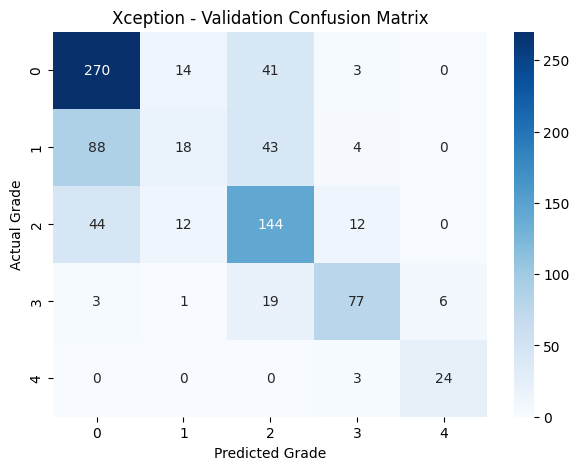

In [ ]:

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print(classification_report(
    all_labels, all_preds,
    labels=[0, 1, 2, 3, 4],
    target_names=["Grade 0", "Grade 1", "Grade 2", "Grade 3", "Grade 4"],
    zero_division=0
))

cm = confusion_matrix(all_labels, all_preds, labels=[0, 1, 2, 3, 4])

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[0, 1, 2, 3, 4],
            yticklabels=[0, 1, 2, 3, 4])
plt.xlabel("Predicted Grade")
plt.ylabel("Actual Grade")
plt.title("Xception - Validation Confusion Matrix")
plt.show()


In [ ]:

print("Model:", model.__class__.__name__)
print("Input size:", model.pretrained_cfg.get("input_size"))
print("Mean:", model.pretrained_cfg.get("mean"))
print("Std:", model.pretrained_cfg.get("std"))


Model: Xception
Input size: (3, 299, 299)
Mean: (0.5, 0.5, 0.5)
Std: (0.5, 0.5, 0.5)


In [18]:

from torchvision import transforms, datasets
from torch.utils.data import DataLoader

# Experiment 2: Xception preprocessing
mean = (0.5, 0.5, 0.5)
std = (0.5, 0.5, 0.5)

val_tf_exp2 = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_tf_exp2 = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((299, 299)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_exp2 = datasets.ImageFolder(f"{base}/train", transform=train_tf_exp2)
val_exp2 = datasets.ImageFolder(f"{base}/val", transform=val_tf_exp2)

train_loader_exp2 = DataLoader(train_exp2, batch_size=16, shuffle=True)
val_loader_exp2 = DataLoader(val_exp2, batch_size=16, shuffle=False)

images, labels = next(iter(train_loader_exp2))
print("Experiment 2 image shape:", images.shape)
print("Train:", len(train_exp2), "| Validation:", len(val_exp2))


Experiment 2 image shape: torch.Size([16, 3, 299, 299])
Train: 5778 | Validation: 826


In [ ]:

import timm
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Fresh pretrained Xception for Experiment 2
model_exp2 = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=True,
    num_classes=5
).to(device)

# Same class weights as Experiment 1
criterion_exp2 = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

optimizer_exp2 = torch.optim.AdamW(
    model_exp2.parameters(),
    lr=0.0001,
    weight_decay=0.0001
)

print("Device:", device)
print("Experiment 2 model ready!")


Device: cuda
Experiment 2 model ready!


In [ ]:

import time
import copy
import os

epochs = 12
patience = 3
best_val_acc = 0.0
best_weights = None
wait = 0
start = time.time()

save_path = "/content/drive/MyDrive/MUFSAL_Xception_Exp2_best.pth"

for epoch in range(epochs):
    model_exp2.train()
    train_correct = 0
    train_total = 0
    train_loss = 0.0

    for images, labels in train_loader_exp2:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_exp2.zero_grad()
        outputs = model_exp2(images)
        loss = criterion_exp2(outputs, labels)
        loss.backward()
        optimizer_exp2.step()

        train_loss += loss.item() * labels.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    model_exp2.eval()
    val_correct = 0
    val_total = 0
    val_loss = 0.0

    with torch.no_grad():
        for images, labels in val_loader_exp2:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_exp2(images)
            loss = criterion_exp2(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    train_acc = 100 * train_correct / train_total
    val_acc = 100 * val_correct / val_total

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Val Loss: {val_loss/val_total:.4f}",
        flush=True
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_weights = copy.deepcopy(model_exp2.state_dict())
        torch.save(best_weights, save_path)
        wait = 0
        print("Best model saved to Google Drive!", flush=True)
    else:
        wait += 1
        if wait >= patience:
            print("Early stopping triggered!")
            break

if best_weights is not None:
    model_exp2.load_state_dict(best_weights)

print(f"Best Validation Accuracy: {best_val_acc:.2f}%")
print(f"Training time: {(time.time()-start)/60:.1f} minutes")


Epoch 1/12 | Train Acc: 45.05% | Val Acc: 50.48% | Val Loss: 1.1573
Best model saved to Google Drive!
Epoch 2/12 | Train Acc: 59.35% | Val Acc: 60.29% | Val Loss: 0.9559
Best model saved to Google Drive!
Epoch 3/12 | Train Acc: 63.36% | Val Acc: 57.75% | Val Loss: 0.9367
Epoch 4/12 | Train Acc: 67.58% | Val Acc: 58.84% | Val Loss: 0.9663
Epoch 5/12 | Train Acc: 71.30% | Val Acc: 58.23% | Val Loss: 1.0123
Early stopping triggered!
Best Validation Accuracy: 60.29%
Training time: 17.7 minutes


In [10]:
from google.colab import drive
import os

drive.mount('/content/drive')

files = os.listdir('/content/drive/MyDrive')

for file in files:
    if 'MUFSAL' in file or 'Xception' in file:
        print(file)

Mounted at /content/drive
MUFSAL_Xception_Exp1_best.pth
MUFSAL_Xception_Exp2_best.pth


In [11]:
import torch

path = '/content/drive/MyDrive/MUFSAL_Xception_Exp2_best.pth'

checkpoint = torch.load(
    path,
    map_location='cpu',
    weights_only=True
)

print("Saved file type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("First keys:", list(checkpoint.keys())[:10])

Saved file type: <class 'collections.OrderedDict'>
First keys: ['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'conv2.weight', 'bn2.weight', 'bn2.bias', 'bn2.running_mean']


In [14]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Train:", len(train_loader.dataset))
print("Validation:", len(val_loader.dataset))
print("Device:", device)

Train: 5778
Validation: 826
Device: cuda


In [15]:
print("Model exists:", "model_exp2" in globals())
print("Timm exists:", "timm" in globals())
print("GPU:", device)

Model exists: False
Timm exists: False
GPU: cuda


In [16]:
!pip install -q timm

import timm
import torch

model_exp2 = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=False,
    num_classes=5
).to(device)

weights = torch.load(
    "/content/drive/MyDrive/MUFSAL_Xception_Exp2_best.pth",
    map_location=device,
    weights_only=True
)

model_exp2.load_state_dict(weights)
model_exp2.eval()

print("Experiment 2 model loaded successfully!")

Experiment 2 model loaded successfully!


In [19]:
import torch
import timm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_exp3 = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=False,
    num_classes=5
).to(device)

model_exp3.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/MUFSAL_Xception_Exp2_best.pth",
        map_location=device,
        weights_only=True
    )
)

print("Experiment 3 model loaded successfully!")

Experiment 3 model loaded successfully!


In [20]:
import torch.nn as nn

criterion_exp3 = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

optimizer_exp3 = torch.optim.AdamW(
    model_exp3.parameters(),
    lr=0.00001,
    weight_decay=0.0001
)

print("Experiment 3 settings ready!")

Experiment 3 settings ready!


In [21]:
import time
import copy
import torch

epochs = 10
patience = 3
wait = 0
best_val_acc = 0
best_weights = None
start = time.time()

save_path = "/content/drive/MyDrive/MUFSAL_Xception_Exp3_best.pth"

for epoch in range(epochs):

    # Training
    model_exp3.train()
    train_correct = 0
    train_total = 0

    for images, labels in train_loader_exp2:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_exp3.zero_grad()
        outputs = model_exp3(images)
        loss = criterion_exp3(outputs, labels)

        loss.backward()
        optimizer_exp3.step()

        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_acc = 100 * train_correct / train_total

    # Validation
    model_exp3.eval()
    val_correct = 0
    val_total = 0
    val_loss = 0

    with torch.no_grad():
        for images, labels in val_loader_exp2:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_exp3(images)
            loss = criterion_exp3(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_acc = 100 * val_correct / val_total
    val_loss /= val_total

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Val Loss: {val_loss:.4f}",
        flush=True
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_weights = copy.deepcopy(model_exp3.state_dict())
        torch.save(best_weights, save_path)
        wait = 0
        print("Best Experiment 3 model saved!", flush=True)
    else:
        wait += 1
        if wait >= patience:
            print("Early stopping triggered!")
            break

if best_weights is not None:
    model_exp3.load_state_dict(best_weights)

print(f"Best Validation Accuracy: {best_val_acc:.2f}%")
print(f"Training time: {(time.time()-start)/60:.1f} minutes")

Epoch 1/10 | Train Acc: 66.70% | Val Acc: 59.81% | Val Loss: 0.9153
Best Experiment 3 model saved!
Epoch 2/10 | Train Acc: 68.10% | Val Acc: 62.83% | Val Loss: 0.8725
Best Experiment 3 model saved!
Epoch 3/10 | Train Acc: 69.73% | Val Acc: 61.02% | Val Loss: 0.8680
Epoch 4/10 | Train Acc: 70.39% | Val Acc: 61.38% | Val Loss: 0.8871
Epoch 5/10 | Train Acc: 71.53% | Val Acc: 60.41% | Val Loss: 0.8993
Early stopping triggered!
Best Validation Accuracy: 62.83%
Training time: 19.3 minutes


In [22]:
import torch
import timm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_best = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=False,
    num_classes=5
).to(device)

model_best.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/MUFSAL_Xception_Exp1_best.pth",
        map_location=device,
        weights_only=True
    )
)

model_best.eval()

print("Best Xception model loaded!")

Best Xception model loaded!


In [23]:
import torch
import timm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_best = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=False,
    num_classes=5
).to(device)

model_best.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/MUFSAL_Xception_Exp1_best.pth",
        map_location=device,
        weights_only=True
    )
)

model_best.eval()

print("Best Xception model loaded!")

Best Xception model loaded!


In [24]:
import torch
from sklearn.metrics import classification_report, confusion_matrix

y_true = []
y_pred = []

model_best.eval()

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model_best(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())

print("Validation Accuracy:",
      round(100 * sum(a == b for a, b in zip(y_true, y_pred)) / len(y_true), 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=["Grade 0", "Grade 1", "Grade 2", "Grade 3", "Grade 4"],
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3, 4]))

Validation Accuracy: 64.53 %

Classification Report:
              precision    recall  f1-score   support

     Grade 0       0.67      0.82      0.74       328
     Grade 1       0.40      0.12      0.18       153
     Grade 2       0.58      0.68      0.63       212
     Grade 3       0.78      0.73      0.75       106
     Grade 4       0.80      0.89      0.84        27

    accuracy                           0.65       826
   macro avg       0.65      0.65      0.63       826
weighted avg       0.61      0.65      0.61       826


Confusion Matrix:
[[270  14  41   3   0]
 [ 88  18  43   4   0]
 [ 44  12 144  12   0]
 [  3   1  19  77   6]
 [  0   0   0   3  24]]


In [25]:
print("Grade 1 total:", y_true.count(1))
print("Grade 1 predicted correctly:",
      sum(t == 1 and p == 1 for t, p in zip(y_true, y_pred)))

print("Grade 1 predicted as Grade 0:",
      sum(t == 1 and p == 0 for t, p in zip(y_true, y_pred)))

Grade 1 total: 153
Grade 1 predicted correctly: 18
Grade 1 predicted as Grade 0: 88


In [26]:
print("Class weights:", class_weights)
print("Classes:", train_loader.dataset.classes)

Class weights: tensor([0.5055, 1.1048, 0.7623, 1.5266, 6.6798])
Classes: ['0', '1', '2', '3', '4']


In [27]:
print("Experiment 1 loss weights:")
print(criterion.weight if "criterion" in globals() else "criterion not found")

print("Experiment 2 loss weights:")
print(criterion_exp2.weight if "criterion_exp2" in globals() else "criterion_exp2 not found")

Experiment 1 loss weights:
criterion not found
Experiment 2 loss weights:
criterion_exp2 not found


In [28]:
import os

files = os.listdir('/content/drive/MyDrive')

for file in files:
    if 'Xception' in file:
        print(file)

MUFSAL_Xception_Exp1_best.pth
MUFSAL_Xception_Exp2_best.pth
MUFSAL_Xception_Exp3_best.pth


In [29]:
print("Experiment 3 history:", history_exp3 if "history_exp3" in globals() else "Not available")
print("Experiment 3 best accuracy:", best_val_acc_exp3 if "best_val_acc_exp3" in globals() else "Not available")

Experiment 3 history: Not available
Experiment 3 best accuracy: Not available


In [30]:
import os

for i in range(1, 4):
    path = f"/content/drive/MyDrive/MUFSAL_Xception_Exp{i}_best.pth"
    print(f"Experiment {i}:", "Saved" if os.path.exists(path) else "Not found")

Experiment 1: Saved
Experiment 2: Saved
Experiment 3: Saved


In [31]:
import timm
import torch
import torch.nn as nn

# Experiment 4: Freeze early layers of Xception
model_exp4 = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=True,
    num_classes=5
).to(device)

# Freeze all layers first
for param in model_exp4.parameters():
    param.requires_grad = False

# Train only the final classification layer
for param in model_exp4.get_classifier().parameters():
    param.requires_grad = True

criterion_exp4 = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

optimizer_exp4 = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model_exp4.parameters()),
    lr=0.0001,
    weight_decay=0.001
)

print("Experiment 4 model ready!")
print("Trainable parameters:",
      sum(p.numel() for p in model_exp4.parameters() if p.requires_grad))

Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
Experiment 4 model ready!
Trainable parameters: 10245


In [32]:
import time
import copy
import os
import torch
from google.colab import drive

drive.mount('/content/drive')

epochs = 12
patience = 4
best_val_acc = 0.0
best_weights = None
wait = 0

save_path = "/content/drive/MyDrive/MUFSAL_Xception_Exp4_best.pth"

history_exp4 = {
    "train_acc": [],
    "val_acc": [],
    "val_loss": []
}

start = time.time()

for epoch in range(epochs):
    model_exp4.train()

    train_correct = 0
    train_total = 0

    for images, labels in train_loader_exp2:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_exp4.zero_grad()
        outputs = model_exp4(images)
        loss = criterion_exp4(outputs, labels)
        loss.backward()
        optimizer_exp4.step()

        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    model_exp4.eval()
    val_correct = 0
    val_total = 0
    val_loss = 0.0

    with torch.no_grad():
        for images, labels in val_loader_exp2:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_exp4(images)
            loss = criterion_exp4(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    train_acc = 100 * train_correct / train_total
    val_acc = 100 * val_correct / val_total
    avg_val_loss = val_loss / val_total

    history_exp4["train_acc"].append(train_acc)
    history_exp4["val_acc"].append(val_acc)
    history_exp4["val_loss"].append(avg_val_loss)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Val Loss: {avg_val_loss:.4f}",
        flush=True
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_weights = copy.deepcopy(model_exp4.state_dict())
        torch.save(best_weights, save_path)
        wait = 0
        print("Best Experiment 4 model saved!", flush=True)
    else:
        wait += 1
        if wait >= patience:
            print("Early stopping triggered!")
            break

if best_weights is not None:
    model_exp4.load_state_dict(best_weights)

print(f"Best Validation Accuracy: {best_val_acc:.2f}%")
print(f"Training time: {(time.time()-start)/60:.1f} minutes")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 1/12 | Train Acc: 28.92% | Val Acc: 41.16% | Val Loss: 1.4707
Best Experiment 4 model saved!
Epoch 2/12 | Train Acc: 36.31% | Val Acc: 38.38% | Val Loss: 1.4611
Epoch 3/12 | Train Acc: 35.62% | Val Acc: 43.46% | Val Loss: 1.4319
Best Experiment 4 model saved!
Epoch 4/12 | Train Acc: 38.66% | Val Acc: 44.31% | Val Loss: 1.3944
Best Experiment 4 model saved!
Epoch 5/12 | Train Acc: 39.62% | Val Acc: 40.68% | Val Loss: 1.3833
Epoch 6/12 | Train Acc: 40.33% | Val Acc: 45.52% | Val Loss: 1.3822
Best Experiment 4 model saved!
Epoch 7/12 | Train Acc: 40.08% | Val Acc: 43.34% | Val Loss: 1.3925
Epoch 8/12 | Train Acc: 39.89% | Val Acc: 42.86% | Val Loss: 1.3728
Epoch 9/12 | Train Acc: 40.58% | Val Acc: 45.28% | Val Loss: 1.3348
Epoch 10/12 | Train Acc: 40.78% | Val Acc: 42.62% | Val Loss: 1.3591
Early stopping triggered!
Best Validation Accuracy: 45.52%
Trainin

In [34]:

import timm
import torch
import torch.nn as nn

# Experiment 5: Partial Fine-tuning
model_exp5 = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=True,
    num_classes=5
).to(device)

# Freeze the backbone
for param in model_exp5.parameters():
    param.requires_grad = False

# Unfreeze the final Xception block
for name, param in model_exp5.named_parameters():
    if name.startswith(("conv3", "bn3", "conv4", "bn4")):
        param.requires_grad = True
    elif name.startswith("block12"):
        param.requires_grad = True

# Unfreeze the classifier
for param in model_exp5.get_classifier().parameters():
    param.requires_grad = True

criterion_exp5 = nn.CrossEntropyLoss(
    weight=class_weights.to(device)
)

optimizer_exp5 = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model_exp5.parameters()),
    lr=0.00002,
    weight_decay=0.001
)

print("Experiment 5 ready!")
print("Trainable parameters:",
      sum(p.numel() for p in model_exp5.parameters() if p.requires_grad))


Experiment 5 ready!
Trainable parameters: 6798629


In [35]:

import torch
import copy
import time

epochs = 12
patience = 4
best_val_acc_exp5 = 0.0
best_weights_exp5 = None
wait = 0

save_path_exp5 = "/content/drive/MyDrive/MUFSAL_Xception_Exp5_best.pth"

start = time.time()

for epoch in range(epochs):
    model_exp5.train()
    train_correct = 0
    train_total = 0

    for images, labels in train_loader_exp2:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_exp5.zero_grad()
        outputs = model_exp5(images)
        loss = criterion_exp5(outputs, labels)
        loss.backward()
        optimizer_exp5.step()

        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    model_exp5.eval()
    val_correct = 0
    val_total = 0
    val_loss = 0.0

    with torch.no_grad():
        for images, labels in val_loader_exp2:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_exp5(images)
            loss = criterion_exp5(outputs, labels)

            val_loss += loss.item() * labels.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    train_acc = 100 * train_correct / train_total
    val_acc = 100 * val_correct / val_total
    avg_val_loss = val_loss / val_total

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Val Loss: {avg_val_loss:.4f}",
        flush=True
    )

    if val_acc > best_val_acc_exp5:
        best_val_acc_exp5 = val_acc
        best_weights_exp5 = copy.deepcopy(model_exp5.state_dict())
        torch.save(best_weights_exp5, save_path_exp5)
        wait = 0
        print("Best Experiment 5 model saved!", flush=True)
    else:
        wait += 1
        if wait >= patience:
            print("Early stopping triggered!")
            break

if best_weights_exp5 is not None:
    model_exp5.load_state_dict(best_weights_exp5)

print(f"Best Validation Accuracy: {best_val_acc_exp5:.2f}%")
print(f"Training time: {(time.time()-start)/60:.1f} minutes")


Epoch 1/12 | Train Acc: 33.68% | Val Acc: 45.88% | Val Loss: 1.4015
Best Experiment 5 model saved!
Epoch 2/12 | Train Acc: 41.90% | Val Acc: 49.39% | Val Loss: 1.2632
Best Experiment 5 model saved!
Epoch 3/12 | Train Acc: 45.57% | Val Acc: 47.22% | Val Loss: 1.2198
Epoch 4/12 | Train Acc: 47.04% | Val Acc: 48.31% | Val Loss: 1.1941
Epoch 5/12 | Train Acc: 48.82% | Val Acc: 49.88% | Val Loss: 1.2006
Best Experiment 5 model saved!
Epoch 6/12 | Train Acc: 50.66% | Val Acc: 49.03% | Val Loss: 1.1943
Epoch 7/12 | Train Acc: 52.28% | Val Acc: 51.82% | Val Loss: 1.1358
Best Experiment 5 model saved!
Epoch 8/12 | Train Acc: 53.10% | Val Acc: 53.15% | Val Loss: 1.1079
Best Experiment 5 model saved!
Epoch 9/12 | Train Acc: 53.37% | Val Acc: 52.78% | Val Loss: 1.1279
Epoch 10/12 | Train Acc: 54.07% | Val Acc: 52.66% | Val Loss: 1.1410
Epoch 11/12 | Train Acc: 56.01% | Val Acc: 53.03% | Val Loss: 1.0944
Epoch 12/12 | Train Acc: 56.21% | Val Acc: 53.75% | Val Loss: 1.1044
Best Experiment 5 model sa

In [36]:
import torch
import timm

model_exp6 = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=False,
    num_classes=5
).to(device)

checkpoint = torch.load(
    "/content/drive/MyDrive/MUFSAL_Xception_Exp1_best.pth",
    map_location=device,
    weights_only=True
)

model_exp6.load_state_dict(checkpoint)
model_exp6.eval()

print("Best Xception model loaded successfully!")

Best Xception model loaded successfully!


In [37]:
import torch

import numpy as np

from sklearn.metrics import classification_report, confusion_matrix

all_true = []

all_pred = []

model_exp6.eval()

with torch.no_grad():

    for images, labels in val_loader_exp2:

        images = images.to(device)

        outputs = model_exp6(images)

        predictions = outputs.argmax(dim=1)

        all_true.extend(labels.numpy())

        all_pred.extend(predictions.cpu().numpy())

all_true = np.array(all_true)

all_pred = np.array(all_pred)

print("Classification Report:")

print(classification_report(

    all_true,

    all_pred,

    labels=[0, 1, 2, 3, 4],

    target_names=["Grade 0", "Grade 1", "Grade 2", "Grade 3", "Grade 4"],

    zero_division=0

))

cm = confusion_matrix(all_true, all_pred, labels=[0, 1, 2, 3, 4])

print("Grade 1 predicted as Grade 0:", cm[1, 0])

print("Grade 1 correctly predicted:", cm[1, 1])

Classification Report:
              precision    recall  f1-score   support

     Grade 0       0.80      0.02      0.05       328
     Grade 1       0.00      0.00      0.00       153
     Grade 2       0.25      0.62      0.36       212
     Grade 3       0.32      0.61      0.42       106
     Grade 4       0.29      0.96      0.45        27

    accuracy                           0.28       826
   macro avg       0.33      0.44      0.25       826
weighted avg       0.43      0.28      0.18       826

Grade 1 predicted as Grade 0: 2
Grade 1 correctly predicted: 0


In [38]:
print("Original validation loader:")
print(val_loader.dataset.transform)

print("\nExperiment 2 validation loader:")
print(val_loader_exp2.dataset.transform)

Original validation loader:
Compose(
    Grayscale(num_output_channels=3)
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Experiment 2 validation loader:
Compose(
    Grayscale(num_output_channels=3)
    Resize(size=(299, 299), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
)


In [39]:
all_true = []
all_pred = []

model_exp6.eval()

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = model_exp6(images)
        predictions = outputs.argmax(dim=1)

        all_true.extend(labels.cpu().numpy())
        all_pred.extend(predictions.cpu().numpy())

print(classification_report(
    all_true,
    all_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=["Grade 0", "Grade 1", "Grade 2", "Grade 3", "Grade 4"],
    zero_division=0
))

              precision    recall  f1-score   support

     Grade 0       0.67      0.82      0.74       328
     Grade 1       0.40      0.12      0.18       153
     Grade 2       0.58      0.68      0.63       212
     Grade 3       0.78      0.73      0.75       106
     Grade 4       0.80      0.89      0.84        27

    accuracy                           0.65       826
   macro avg       0.65      0.65      0.63       826
weighted avg       0.61      0.65      0.61       826



In [40]:
import numpy as np
from sklearn.metrics import f1_score

all_probs = []
all_true = []

model_exp6.eval()

with torch.no_grad():
    for images, labels in val_loader:
        outputs = model_exp6(images.to(device))
        probs = torch.softmax(outputs, dim=1)

        all_probs.append(probs.cpu().numpy())
        all_true.extend(labels.numpy())

all_probs = np.concatenate(all_probs)
all_true = np.array(all_true)

for boost in [1.0, 1.1, 1.2, 1.3, 1.5, 2.0]:
    adjusted = all_probs.copy()
    adjusted[:, 1] *= boost

    preds = adjusted.argmax(axis=1)

    print(
        f"Boost: {boost:.1f} | "
        f"Accuracy: {(preds == all_true).mean()*100:.2f}% | "
        f"Macro F1: {f1_score(all_true, preds, average='macro'):.3f} | "
        f"Grade 1 F1: {f1_score(all_true, preds, labels=[1], average='macro', zero_division=0):.3f}"
    )

Boost: 1.0 | Accuracy: 64.53% | Macro F1: 0.628 | Grade 1 F1: 0.182
Boost: 1.1 | Accuracy: 64.65% | Macro F1: 0.630 | Grade 1 F1: 0.190
Boost: 1.2 | Accuracy: 64.65% | Macro F1: 0.630 | Grade 1 F1: 0.190
Boost: 1.3 | Accuracy: 64.29% | Macro F1: 0.628 | Grade 1 F1: 0.187
Boost: 1.5 | Accuracy: 64.16% | Macro F1: 0.629 | Grade 1 F1: 0.194
Boost: 2.0 | Accuracy: 64.29% | Macro F1: 0.634 | Grade 1 F1: 0.223


In [41]:
import hashlib
from collections import defaultdict

hashes = defaultdict(list)

for path, label in train.samples:
    with open(path, "rb") as f:
        h = hashlib.md5(f.read()).hexdigest()
    hashes[h].append((path, label))

duplicates = [v for v in hashes.values() if len(v) > 1]

print("Total training images:", len(train))
print("Exact duplicate groups:", len(duplicates))
print("Extra duplicate copies:",
      sum(len(g) - 1 for g in duplicates))

Total training images: 5778
Exact duplicate groups: 0
Extra duplicate copies: 0


In [42]:
from sklearn.metrics import accuracy_score, f1_score
import torch

tta_true = []
tta_pred = []

model_exp6.eval()

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        original = torch.softmax(model_exp6(images), dim=1)
        flipped = torch.softmax(
            model_exp6(torch.flip(images, dims=[3])), dim=1
        )

        avg_probs = (original + flipped) / 2
        predictions = avg_probs.argmax(dim=1)

        tta_true.extend(labels.numpy())
        tta_pred.extend(predictions.cpu().numpy())

print("TTA Accuracy:",
      round(accuracy_score(tta_true, tta_pred) * 100, 2))

print("TTA Macro F1:",
      round(f1_score(tta_true, tta_pred, average="macro"), 3))

print("TTA Grade 1 F1:",
      round(f1_score(
          tta_true, tta_pred,
          labels=[1], average="macro",
          zero_division=0
      ), 3))

TTA Accuracy: 64.89
TTA Macro F1: 0.632
TTA Grade 1 F1: 0.172


In [43]:
import torch
import torch.nn as nn
import timm

model_exp6 = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=False,
    num_classes=5
).to(device)

model_exp6.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/MUFSAL_Xception_Exp1_best.pth",
        map_location=device,
        weights_only=True
    )
)

criterion_exp6 = nn.CrossEntropyLoss(
    label_smoothing=0.05
)

optimizer_exp6 = torch.optim.AdamW(
    model_exp6.parameters(),
    lr=0.000005,
    weight_decay=0.001
)

print("Experiment 6 ready!")

Experiment 6 ready!


In [44]:
import torch
import copy
import time
from sklearn.metrics import f1_score, accuracy_score

epochs = 20
patience = 5
wait = 0

best_f1_exp6 = -1.0
best_acc_exp6 = 0.0
best_weights_exp6 = None

save_path_exp6 = "/content/drive/MyDrive/MUFSAL_Xception_Exp6_best.pth"

start = time.time()

for epoch in range(epochs):

    # Training
    model_exp6.train()
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_exp6.zero_grad()

        outputs = model_exp6(images)
        loss = criterion_exp6(outputs, labels)

        loss.backward()
        optimizer_exp6.step()

        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_acc = 100 * train_correct / train_total

    # Validation
    model_exp6.eval()
    val_true = []
    val_pred = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)

            outputs = model_exp6(images)
            predictions = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_acc = accuracy_score(val_true, val_pred) * 100
    val_f1 = f1_score(
        val_true, val_pred,
        average="macro",
        zero_division=0
    )

    grade1_f1 = f1_score(
        val_true, val_pred,
        labels=[1],
        average="macro",
        zero_division=0
    )

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Macro F1: {val_f1:.3f} | "
        f"Grade 1 F1: {grade1_f1:.3f}",
        flush=True
    )

    # Save best model based on Macro F1
    if val_f1 > best_f1_exp6:
        best_f1_exp6 = val_f1
        best_acc_exp6 = val_acc

        best_weights_exp6 = copy.deepcopy(
            model_exp6.state_dict()
        )

        torch.save(best_weights_exp6, save_path_exp6)

        wait = 0
        print("Best Experiment 6 model saved!", flush=True)

    else:
        wait += 1

        if wait >= patience:
            print("Early stopping triggered!")
            break

if best_weights_exp6 is not None:
    model_exp6.load_state_dict(best_weights_exp6)

print("\nExperiment 6 Finished!")
print(f"Best Validation Accuracy: {best_acc_exp6:.2f}%")
print(f"Best Macro F1: {best_f1_exp6:.3f}")
print(f"Training Time: {(time.time()-start)/60:.1f} minutes")

Epoch 1/20 | Train Acc: 98.20% | Val Acc: 63.68% | Macro F1: 0.646 | Grade 1 F1: 0.295
Best Experiment 6 model saved!
Epoch 2/20 | Train Acc: 98.60% | Val Acc: 62.71% | Macro F1: 0.634 | Grade 1 F1: 0.243
Epoch 3/20 | Train Acc: 98.93% | Val Acc: 62.59% | Macro F1: 0.640 | Grade 1 F1: 0.281
Epoch 4/20 | Train Acc: 98.93% | Val Acc: 63.20% | Macro F1: 0.639 | Grade 1 F1: 0.272
Epoch 5/20 | Train Acc: 99.00% | Val Acc: 63.56% | Macro F1: 0.640 | Grade 1 F1: 0.278
Epoch 6/20 | Train Acc: 99.43% | Val Acc: 62.95% | Macro F1: 0.640 | Grade 1 F1: 0.280
Early stopping triggered!

Experiment 6 Finished!
Best Validation Accuracy: 63.68%
Best Macro F1: 0.646
Training Time: 13.9 minutes


In [45]:
from sklearn.metrics import classification_report

model_exp6.eval()
true_labels = []
pred_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        outputs = model_exp6(images.to(device))
        predictions = outputs.argmax(1)

        true_labels.extend(labels.numpy())
        pred_labels.extend(predictions.cpu().numpy())

print(classification_report(
    true_labels,
    pred_labels,
    target_names=[f"Grade {i}" for i in range(5)],
    zero_division=0
))

              precision    recall  f1-score   support

     Grade 0       0.70      0.75      0.72       328
     Grade 1       0.38      0.24      0.29       153
     Grade 2       0.58      0.66      0.62       212
     Grade 3       0.75      0.75      0.75       106
     Grade 4       0.80      0.89      0.84        27

    accuracy                           0.64       826
   macro avg       0.64      0.66      0.65       826
weighted avg       0.62      0.64      0.62       826



In [46]:
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

# Experiment 7: Data Augmentation

train_transform_exp7 = transforms.Compose([
    Denoise(),
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=5),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset_exp7 = datasets.ImageFolder(
    f"{base}/train",
    transform=train_transform_exp7
)

train_loader_exp7 = DataLoader(
    train_dataset_exp7,
    batch_size=16,
    shuffle=True,
    num_workers=2
)

print("Experiment 7 Data Augmentation ready!")
print("Training images:", len(train_dataset_exp7))

Experiment 7 Data Augmentation ready!
Training images: 5778


In [49]:

import torch
import copy
import time
from sklearn.metrics import accuracy_score, f1_score

epochs = 20
patience = 5
wait = 0

best_f1_exp7 = -1.0
best_acc_exp7 = 0.0
best_grade1_exp7 = 0.0
best_weights_exp7 = None

save_path_exp7 = "/content/drive/MyDrive/MUFSAL_Xception_Exp7_best.pth"

start = time.time()

for epoch in range(epochs):

    # Training
    model_exp7.train()
    train_correct = 0
    train_total = 0

    for images, labels in train_loader_exp7:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_exp7.zero_grad()

        outputs = model_exp7(images)
        loss = criterion_exp7(outputs, labels)

        loss.backward()
        optimizer_exp7.step()

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_acc = 100 * train_correct / train_total

    # Validation: original preprocessing
    model_exp7.eval()
    val_true = []
    val_pred = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)

            outputs = model_exp7(images)
            predictions = outputs.argmax(dim=1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_acc = accuracy_score(val_true, val_pred) * 100
    val_f1 = f1_score(
        val_true, val_pred,
        average="macro",
        zero_division=0
    )
    grade1_f1 = f1_score(
        val_true, val_pred,
        labels=[1],
        average="macro",
        zero_division=0
    )

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Macro F1: {val_f1:.3f} | "
        f"Grade 1 F1: {grade1_f1:.3f}",
        flush=True
    )

    # Save best based on Macro F1
    if val_f1 > best_f1_exp7:
        best_f1_exp7 = val_f1
        best_acc_exp7 = val_acc
        best_grade1_exp7 = grade1_f1

        best_weights_exp7 = copy.deepcopy(
            model_exp7.state_dict()
        )

        torch.save(best_weights_exp7, save_path_exp7)

        wait = 0
        print("Best Experiment 7 model saved!", flush=True)

    else:
        wait += 1

        if wait >= patience:
            print("Early stopping triggered!")
            break

if best_weights_exp7 is not None:
    model_exp7.load_state_dict(best_weights_exp7)

print("\nExperiment 7 Finished!")
print(f"Best Validation Accuracy: {best_acc_exp7:.2f}%")
print(f"Best Macro F1: {best_f1_exp7:.3f}")
print(f"Best Grade 1 F1: {best_grade1_exp7:.3f}")
print(f"Training Time: {(time.time()-start)/60:.1f} minutes")


Epoch 1/20 | Train Acc: 85.41% | Val Acc: 62.47% | Macro F1: 0.641 | Grade 1 F1: 0.297
Best Experiment 7 model saved!
Epoch 2/20 | Train Acc: 87.19% | Val Acc: 63.20% | Macro F1: 0.646 | Grade 1 F1: 0.305
Best Experiment 7 model saved!
Epoch 3/20 | Train Acc: 88.32% | Val Acc: 64.29% | Macro F1: 0.645 | Grade 1 F1: 0.278
Epoch 4/20 | Train Acc: 88.13% | Val Acc: 64.41% | Macro F1: 0.650 | Grade 1 F1: 0.272
Best Experiment 7 model saved!
Epoch 5/20 | Train Acc: 89.08% | Val Acc: 63.44% | Macro F1: 0.654 | Grade 1 F1: 0.317
Best Experiment 7 model saved!
Epoch 6/20 | Train Acc: 88.98% | Val Acc: 64.16% | Macro F1: 0.647 | Grade 1 F1: 0.268
Epoch 7/20 | Train Acc: 89.48% | Val Acc: 63.68% | Macro F1: 0.658 | Grade 1 F1: 0.326
Best Experiment 7 model saved!
Epoch 8/20 | Train Acc: 90.97% | Val Acc: 61.74% | Macro F1: 0.654 | Grade 1 F1: 0.321
Epoch 9/20 | Train Acc: 91.62% | Val Acc: 62.11% | Macro F1: 0.653 | Grade 1 F1: 0.331
Epoch 10/20 | Train Acc: 91.29% | Val Acc: 62.71% | Macro F1: 

In [48]:
import torch
import torch.nn as nn
import timm

model_exp7 = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=False,
    num_classes=5
).to(device)

model_exp7.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/MUFSAL_Xception_Exp1_best.pth",
        map_location=device,
        weights_only=True
    )
)

criterion_exp7 = nn.CrossEntropyLoss(
    label_smoothing=0.05
)

optimizer_exp7 = torch.optim.AdamW(
    model_exp7.parameters(),
    lr=0.000005,
    weight_decay=0.001
)

print("Experiment 7 model ready!")
print("Train loader exists:", "train_loader_exp7" in globals())

Experiment 7 model ready!
Train loader exists: True


In [50]:
import os

path = "/content/drive/MyDrive/MUFSAL_Xception_Exp7_best.pth"

print("Experiment 7 saved:", os.path.exists(path))

Experiment 7 saved: True


In [51]:
import torch
import timm

model_exp1 = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=False,
    num_classes=5
).to(device)

model_exp1.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/MUFSAL_Xception_Exp1_best.pth",
        map_location=device,
        weights_only=True
    )
)

model_exp1.eval()

print("Experiment 1 loaded successfully!")

Experiment 1 loaded successfully!


In [52]:

model_exp7.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/MUFSAL_Xception_Exp7_best.pth",
        map_location=device,
        weights_only=True
    )
)

model_exp7.eval()

print("Experiment 7 loaded successfully!")


Experiment 7 loaded successfully!


In [53]:

import numpy as np
import torch

all_true = []
all_probs1 = []
all_probs7 = []

model_exp1.eval()
model_exp7.eval()

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        probs1 = torch.softmax(model_exp1(images), dim=1)
        probs7 = torch.softmax(model_exp7(images), dim=1)

        all_probs1.append(probs1.cpu().numpy())
        all_probs7.append(probs7.cpu().numpy())
        all_true.extend(labels.cpu().numpy())

all_true = np.array(all_true)
all_probs1 = np.concatenate(all_probs1)
all_probs7 = np.concatenate(all_probs7)

print("Ensemble predictions ready!")
print("Total validation images:", len(all_true))


Ensemble predictions ready!
Total validation images: 826


In [54]:

from sklearn.metrics import accuracy_score, f1_score

best_f1_exp8 = -1
best_weight_exp8 = None

for weight in [0.0, 0.25, 0.5, 0.75, 1.0]:

    ensemble_probs = (
        weight * all_probs1 +
        (1 - weight) * all_probs7
    )

    predictions = ensemble_probs.argmax(axis=1)

    acc = accuracy_score(all_true, predictions) * 100

    macro_f1 = f1_score(
        all_true, predictions,
        average="macro",
        zero_division=0
    )

    grade1_f1 = f1_score(
        all_true, predictions,
        labels=[1],
        average="macro",
        zero_division=0
    )

    print(
        f"Exp1 Weight: {weight:.2f} | "
        f"Accuracy: {acc:.2f}% | "
        f"Macro F1: {macro_f1:.3f} | "
        f"Grade 1 F1: {grade1_f1:.3f}"
    )

    if macro_f1 > best_f1_exp8:
        best_f1_exp8 = macro_f1
        best_weight_exp8 = weight

print("\nBest Ensemble Weight:", best_weight_exp8)
print("Best Macro F1:", round(best_f1_exp8, 3))


Exp1 Weight: 0.00 | Accuracy: 63.32% | Macro F1: 0.659 | Grade 1 F1: 0.324
Exp1 Weight: 0.25 | Accuracy: 63.08% | Macro F1: 0.645 | Grade 1 F1: 0.271
Exp1 Weight: 0.50 | Accuracy: 63.80% | Macro F1: 0.632 | Grade 1 F1: 0.212
Exp1 Weight: 0.75 | Accuracy: 64.53% | Macro F1: 0.629 | Grade 1 F1: 0.189
Exp1 Weight: 1.00 | Accuracy: 64.53% | Macro F1: 0.628 | Grade 1 F1: 0.182

Best Ensemble Weight: 0.0
Best Macro F1: 0.659


In [55]:

import json

exp8_results = {
    "experiment": 8,
    "method": "Ensemble Exp1 + Exp7",
    "best_exp1_weight": best_weight_exp8,
    "best_macro_f1": best_f1_exp8,
    "best_accuracy": 63.32,
    "grade1_f1": 0.324
}

save_path = "/content/drive/MyDrive/MUFSAL_Exp8_results.json"

with open(save_path, "w") as f:
    json.dump(exp8_results, f, indent=4)

print("Experiment 8 results saved successfully!")


Experiment 8 results saved successfully!


In [56]:

from sklearn.metrics import classification_report, confusion_matrix

predictions_exp7 = all_probs7.argmax(axis=1)

print("Experiment 7 Classification Report:\n")

print(classification_report(
    all_true,
    predictions_exp7,
    target_names=[f"Grade {i}" for i in range(5)],
    digits=3,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(all_true, predictions_exp7))


Experiment 7 Classification Report:

              precision    recall  f1-score   support

     Grade 0      0.664     0.765     0.711       328
     Grade 1      0.351     0.301     0.324       153
     Grade 2      0.654     0.561     0.604       212
     Grade 3      0.786     0.764     0.775       106
     Grade 4      0.812     0.963     0.881        27

    accuracy                          0.633       826
   macro avg      0.654     0.671     0.659       826
weighted avg      0.624     0.633     0.626       826


Confusion Matrix:
[[251  53  22   2   0]
 [ 78  46  25   4   0]
 [ 47  31 119  15   0]
 [  2   1  16  81   6]
 [  0   0   0   1  26]]


In [57]:

from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

report_exp7 = classification_report(
    all_true,
    predictions_exp7,
    target_names=[f"Grade {i}" for i in range(5)],
    digits=3,
    zero_division=0
)

matrix_exp7 = confusion_matrix(all_true, predictions_exp7)

save_path = "/content/drive/MyDrive/MUFSAL_Exp7_Evaluation.txt"

with open(save_path, "w") as f:
    f.write("Experiment 7 - Validation Evaluation\n\n")
    f.write(report_exp7)
    f.write("\n\nConfusion Matrix:\n")
    f.write(np.array2string(matrix_exp7))

print("Experiment 7 evaluation saved successfully!")


Experiment 7 evaluation saved successfully!


In [58]:

# Experiment 9: Grade 1 Probability Adjustment

from sklearn.metrics import accuracy_score, f1_score

for boost in [1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.5, 3.0]:

    adjusted_probs = all_probs7.copy()
    adjusted_probs[:, 1] *= boost

    predictions = adjusted_probs.argmax(axis=1)

    accuracy = accuracy_score(all_true, predictions) * 100
    macro_f1 = f1_score(
        all_true, predictions,
        average="macro",
        zero_division=0
    )
    grade1_f1 = f1_score(
        all_true, predictions,
        labels=[1],
        average="macro",
        zero_division=0
    )

    print(
        f"Boost: {boost:.1f} | "
        f"Accuracy: {accuracy:.2f}% | "
        f"Macro F1: {macro_f1:.3f} | "
        f"Grade 1 F1: {grade1_f1:.3f}"
    )


Boost: 1.0 | Accuracy: 63.32% | Macro F1: 0.659 | Grade 1 F1: 0.324
Boost: 1.2 | Accuracy: 63.44% | Macro F1: 0.662 | Grade 1 F1: 0.341
Boost: 1.4 | Accuracy: 62.11% | Macro F1: 0.655 | Grade 1 F1: 0.331
Boost: 1.6 | Accuracy: 61.62% | Macro F1: 0.653 | Grade 1 F1: 0.339
Boost: 1.8 | Accuracy: 61.50% | Macro F1: 0.654 | Grade 1 F1: 0.350
Boost: 2.0 | Accuracy: 60.65% | Macro F1: 0.650 | Grade 1 F1: 0.349
Boost: 2.5 | Accuracy: 59.81% | Macro F1: 0.646 | Grade 1 F1: 0.349
Boost: 3.0 | Accuracy: 58.72% | Macro F1: 0.643 | Grade 1 F1: 0.357


In [59]:

import json

exp9_results = {
    "experiment": 9,
    "method": "Grade 1 Probability Adjustment",
    "best_boost": 1.2,
    "accuracy": 63.44,
    "macro_f1": 0.662,
    "grade1_f1": 0.341
}

with open("/content/drive/MyDrive/MUFSAL_Exp9_results.json", "w") as f:
    json.dump(exp9_results, f, indent=4)

print("Experiment 9 saved successfully!")


Experiment 9 saved successfully!


In [60]:

# Experiment 10: Analyze Grade 1 Misclassifications

import numpy as np
from sklearn.metrics import confusion_matrix

predictions_exp7 = all_probs7.argmax(axis=1)

cm = confusion_matrix(
    all_true,
    predictions_exp7,
    labels=[0, 1, 2, 3, 4]
)

print("Grade 1 Analysis")
print("-------------------------")
print("Total Grade 1 images:", cm[1].sum())
print("Correct predictions:", cm[1, 1])
print("Predicted as Grade 0:", cm[1, 0])
print("Predicted as Grade 2:", cm[1, 2])
print("Predicted as Grade 3:", cm[1, 3])
print("Predicted as Grade 4:", cm[1, 4])


Grade 1 Analysis
-------------------------
Total Grade 1 images: 153
Correct predictions: 46
Predicted as Grade 0: 78
Predicted as Grade 2: 25
Predicted as Grade 3: 4
Predicted as Grade 4: 0


In [61]:

import torch
import torch.nn as nn
import torch.nn.functional as F

class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0):
        super().__init__()
        self.gamma = gamma

    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(
            inputs, targets, reduction="none"
        )
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        return focal_loss.mean()

criterion_exp10 = FocalLoss(gamma=2.0)

print("Experiment 10 Focal Loss ready!")


Experiment 10 Focal Loss ready!


In [62]:

import timm
import torch
import torch.nn as nn

model_exp10 = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=False,
    num_classes=5
).to(device)

model_exp10.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/MUFSAL_Xception_Exp7_best.pth",
        map_location=device,
        weights_only=True
    )
)

optimizer_exp10 = torch.optim.AdamW(
    model_exp10.parameters(),
    lr=0.000005,
    weight_decay=0.001
)

print("Experiment 10 model ready!")


Experiment 10 model ready!


In [63]:

import torch
import numpy as np
from sklearn.metrics import f1_score, accuracy_score

epochs_exp10 = 20
patience_exp10 = 5
best_f1_exp10 = -1
wait_exp10 = 0

save_path_exp10 = "/content/drive/MyDrive/MUFSAL_Xception_Exp10_best.pth"

for epoch in range(epochs_exp10):

    model_exp10.train()
    train_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader_exp7:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_exp10.zero_grad()

        outputs = model_exp10(images)
        loss = criterion_exp10(outputs, labels)

        loss.backward()
        optimizer_exp10.step()

        train_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_acc = 100 * correct / total
    avg_train_loss = train_loss / total

    model_exp10.eval()
    val_true = []
    val_pred = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)

            outputs = model_exp10(images)
            predictions = outputs.argmax(1)

            val_true.extend(labels.numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_acc = accuracy_score(val_true, val_pred) * 100
    macro_f1 = f1_score(
        val_true, val_pred,
        average="macro",
        zero_division=0
    )
    grade1_f1 = f1_score(
        val_true, val_pred,
        labels=[1],
        average="macro",
        zero_division=0
    )

    print(
        f"Epoch {epoch+1}/{epochs_exp10} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Macro F1: {macro_f1:.3f} | "
        f"Grade 1 F1: {grade1_f1:.3f}",
        flush=True
    )

    if macro_f1 > best_f1_exp10:
        best_f1_exp10 = macro_f1
        wait_exp10 = 0

        torch.save(
            model_exp10.state_dict(),
            save_path_exp10
        )

        print("Best model saved!", flush=True)

    else:
        wait_exp10 += 1

        if wait_exp10 >= patience_exp10:
            print("Early stopping!", flush=True)
            break

print("\nExperiment 10 completed!")
print("Best Macro F1:", round(best_f1_exp10, 3))
print("Saved to:", save_path_exp10)


Epoch 1/20 | Train Loss: 0.0784 | Train Acc: 93.46% | Val Acc: 61.26% | Macro F1: 0.649 | Grade 1 F1: 0.340
Best model saved!
Epoch 2/20 | Train Loss: 0.0723 | Train Acc: 93.86% | Val Acc: 62.83% | Macro F1: 0.654 | Grade 1 F1: 0.331
Best model saved!
Epoch 3/20 | Train Loss: 0.0703 | Train Acc: 93.94% | Val Acc: 61.74% | Macro F1: 0.647 | Grade 1 F1: 0.341
Epoch 4/20 | Train Loss: 0.0559 | Train Acc: 95.05% | Val Acc: 62.35% | Macro F1: 0.651 | Grade 1 F1: 0.335
Epoch 5/20 | Train Loss: 0.0503 | Train Acc: 95.12% | Val Acc: 62.47% | Macro F1: 0.647 | Grade 1 F1: 0.279
Epoch 6/20 | Train Loss: 0.0498 | Train Acc: 95.21% | Val Acc: 60.90% | Macro F1: 0.638 | Grade 1 F1: 0.324
Epoch 7/20 | Train Loss: 0.0507 | Train Acc: 95.07% | Val Acc: 61.50% | Macro F1: 0.637 | Grade 1 F1: 0.303
Early stopping!

Experiment 10 completed!
Best Macro F1: 0.654
Saved to: /content/drive/MyDrive/MUFSAL_Xception_Exp10_best.pth


In [64]:

import torch
import numpy as np
from torch.utils.data import DataLoader, WeightedRandomSampler

targets_exp11 = np.array(train_dataset_exp7.targets)

class_counts_exp11 = np.bincount(targets_exp11, minlength=5)

class_weights_exp11 = 1.0 / np.sqrt(class_counts_exp11)

sample_weights_exp11 = class_weights_exp11[targets_exp11]

sampler_exp11 = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights_exp11),
    num_samples=len(sample_weights_exp11),
    replacement=True
)

train_loader_exp11 = DataLoader(
    train_dataset_exp7,
    batch_size=16,
    sampler=sampler_exp11,
    num_workers=2,
    pin_memory=True
)

print("Class counts:", class_counts_exp11)
print("Experiment 11 Balanced Sampling ready!")


Class counts: [2286 1046 1516  757  173]
Experiment 11 Balanced Sampling ready!


In [65]:

import torch
import timm
import torch.nn as nn

model_exp11 = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=False,
    num_classes=5
).to(device)

model_exp11.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/MUFSAL_Xception_Exp7_best.pth",
        map_location=device,
        weights_only=True
    )
)

criterion_exp11 = nn.CrossEntropyLoss(
    label_smoothing=0.05
)

optimizer_exp11 = torch.optim.AdamW(
    model_exp11.parameters(),
    lr=0.000005,
    weight_decay=0.001
)

print("Experiment 11 Xception model ready!")


Experiment 11 Xception model ready!


In [66]:

import torch
from sklearn.metrics import accuracy_score, f1_score

epochs_exp11 = 20
patience_exp11 = 5
best_f1_exp11 = -1
best_acc_exp11 = 0
best_epoch_exp11 = 0
wait_exp11 = 0

save_path_exp11 = "/content/drive/MyDrive/MUFSAL_Xception_Exp11_best.pth"

for epoch in range(epochs_exp11):

    model_exp11.train()
    train_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader_exp11:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_exp11.zero_grad()

        outputs = model_exp11(images)
        loss = criterion_exp11(outputs, labels)

        loss.backward()
        optimizer_exp11.step()

        train_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_acc = 100 * correct / total
    avg_train_loss = train_loss / total

    model_exp11.eval()
    val_true = []
    val_pred = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)

            outputs = model_exp11(images)
            predictions = outputs.argmax(1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_acc = accuracy_score(val_true, val_pred) * 100

    macro_f1 = f1_score(
        val_true,
        val_pred,
        average="macro",
        zero_division=0
    )

    grade1_f1 = f1_score(
        val_true,
        val_pred,
        labels=[1],
        average="macro",
        zero_division=0
    )

    print(
        f"Epoch {epoch+1}/{epochs_exp11} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Macro F1: {macro_f1:.3f} | "
        f"Grade 1 F1: {grade1_f1:.3f}",
        flush=True
    )

    if macro_f1 > best_f1_exp11:
        best_f1_exp11 = macro_f1
        best_acc_exp11 = val_acc
        best_epoch_exp11 = epoch + 1
        wait_exp11 = 0

        torch.save(
            model_exp11.state_dict(),
            save_path_exp11
        )

        print("Best model saved!", flush=True)

    else:
        wait_exp11 += 1

        if wait_exp11 >= patience_exp11:
            print("Early stopping!", flush=True)
            break

print("\nExperiment 11 completed!")
print("Best Epoch:", best_epoch_exp11)
print("Validation Accuracy:", round(best_acc_exp11, 2), "%")
print("Best Macro F1:", round(best_f1_exp11, 3))
print("Saved to:", save_path_exp11)


Epoch 1/20 | Train Loss: 0.3937 | Train Acc: 93.35% | Val Acc: 61.14% | Macro F1: 0.653 | Grade 1 F1: 0.345
Best model saved!
Epoch 2/20 | Train Loss: 0.3785 | Train Acc: 94.17% | Val Acc: 63.20% | Macro F1: 0.655 | Grade 1 F1: 0.341
Best model saved!
Epoch 3/20 | Train Loss: 0.3634 | Train Acc: 94.70% | Val Acc: 61.74% | Macro F1: 0.656 | Grade 1 F1: 0.366
Best model saved!
Epoch 4/20 | Train Loss: 0.3589 | Train Acc: 95.33% | Val Acc: 61.74% | Macro F1: 0.654 | Grade 1 F1: 0.343
Epoch 5/20 | Train Loss: 0.3595 | Train Acc: 95.22% | Val Acc: 61.26% | Macro F1: 0.647 | Grade 1 F1: 0.345
Epoch 6/20 | Train Loss: 0.3481 | Train Acc: 95.83% | Val Acc: 61.86% | Macro F1: 0.647 | Grade 1 F1: 0.325
Epoch 7/20 | Train Loss: 0.3453 | Train Acc: 95.71% | Val Acc: 61.02% | Macro F1: 0.636 | Grade 1 F1: 0.285
Epoch 8/20 | Train Loss: 0.3385 | Train Acc: 96.28% | Val Acc: 61.74% | Macro F1: 0.650 | Grade 1 F1: 0.318
Early stopping!

Experiment 11 completed!
Best Epoch: 3
Validation Accuracy: 61.74

In [1]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [2]:

%pip install -q timm cleanlab

import torch
import timm
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Libraries ready!")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 kB 13.0 MB/s eta 0:00:00
Device: cuda
Libraries ready!


In [3]:

import torch
import timm

model_exp12 = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=False,
    num_classes=5
).to(device)

model_exp12.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/MUFSAL_Xception_Exp7_best.pth",
        map_location=device,
        weights_only=True
    )
)

model_exp12.eval()

print("Xception loaded successfully!")


Xception loaded successfully!


In [4]:

import os

print("Dataset folders:")

for path in [
    "/content",
    "/content/drive/MyDrive"
]:
    print(f"\n{path}")
    print(os.listdir(path)[:30])


Dataset folders:

/content
['.config', 'drive', 'sample_data']

/content/drive/MyDrive
['Colab Notebooks', 'نموذج بدون عنوان (2).gform', 'نموذج بدون عنوان (1).gform', 'CV.pdf', '\u200e\u2068نورة الموسى\u2069 2.pdf', 'IMG_3676.jpeg', 'IMG_9515.jpeg', 'IMG_9516.png', 'IMG_9517.jpeg', 'IMG_3677.png', 'IMG_3678.png', 'قالب اسماء المدعوين.gsheet', 'سسمر.pdf', 'IMG_5109.png', 'IMG_5110.jpeg', 'IMG_5113.jpeg', 'CD3CF55D-F6E3-4BFD-B7A7-D901D1DD5C81.jpeg', 'Course .jpeg', 'نموذج بدون عنوان.gform', '\u200e\u2068معالجة أوضاع التسجيل 5 ezc \u2069.pdf', 'IMG_6629.png', 'جامعة الملك سعود  البوابة الإلكترونية للنظام الأكاديمي (1).jpeg', 'IMG_6630.jpeg', 'جامعة الملك سعود  البوابة الإلكترونية للنظام الأكاديمي.jpeg', 'IMG_6634 (1).jpeg', 'IMG_6634.jpeg', '\u200e\u2068معالجة أوضاع \u2069.pdf', 'MUFSAL_Xception_Exp1_best.pth', 'MUFSAL_Xception_Exp2_best.pth', 'MUFSAL_Xception_Exp3_best.pth']


In [5]:

%pip install -q kagglehub

import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "shashwatwork/knee-osteoarthritis-dataset-with-severity"
)

print("Dataset downloaded!")
print("Path:", dataset_path)
print("Folders:", os.listdir(dataset_path))


100%|██████████| 204M/204M [00:01<00:00, 144MB/s]

Extracting files...


Dataset downloaded!
Path: /root/.cache/kagglehub/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/versions/1
Folders: ['auto_test', 'val', 'train', 'test']


In [6]:

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform_exp12 = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset_exp12 = datasets.ImageFolder(
    root=f"{dataset_path}/train",
    transform=transform_exp12
)

train_loader_exp12 = DataLoader(
    train_dataset_exp12,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

print("Training images:", len(train_dataset_exp12))
print("Classes:", train_dataset_exp12.classes)
print("Dataset ready!")


Training images: 5778
Classes: ['0', '1', '2', '3', '4']
Dataset ready!


In [7]:

import torch
import numpy as np

model_exp12.eval()

train_probs_exp12 = []
train_labels_exp12 = []

with torch.inference_mode():
    for images, labels in train_loader_exp12:
        images = images.to(device)

        outputs = model_exp12(images)
        probs = torch.softmax(outputs, dim=1)

        train_probs_exp12.append(probs.cpu().numpy())
        train_labels_exp12.extend(labels.numpy())

train_probs_exp12 = np.concatenate(train_probs_exp12)
train_labels_exp12 = np.array(train_labels_exp12)

print("Predictions ready!")
print("Shape:", train_probs_exp12.shape)


Predictions ready!
Shape: (5778, 5)


In [8]:

from cleanlab.filter import find_label_issues
import numpy as np

suspected_issues_exp12 = find_label_issues(
    labels=train_labels_exp12,
    pred_probs=train_probs_exp12,
    return_indices_ranked_by="self_confidence"
)

print("Potential label issues:", len(suspected_issues_exp12))
print("First 10 suspicious indices:", suspected_issues_exp12[:10])


Potential label issues: 473
First 10 suspicious indices: [2288  956 4442 1767 1256 1235 2556 1692  678 1462]


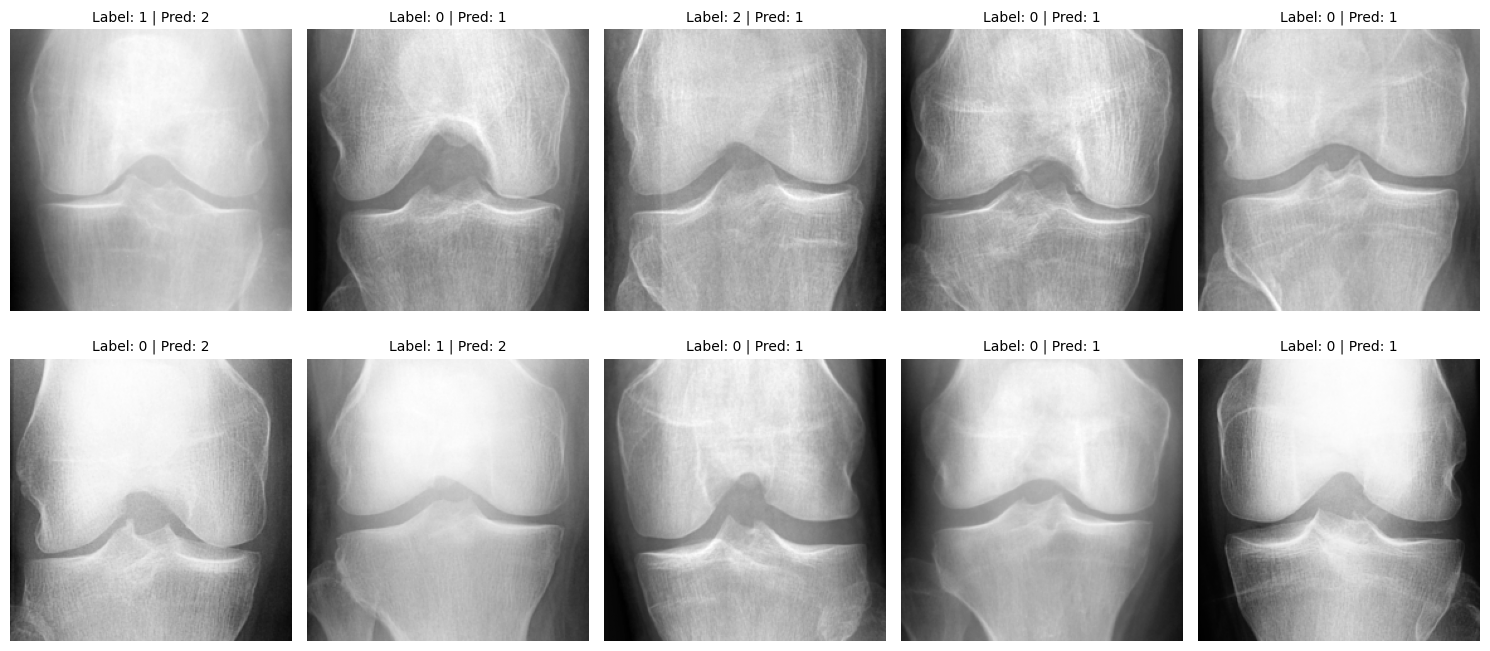

In [9]:

import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for ax, idx in zip(axes.flat, suspected_issues_exp12[:10]):
    image_path, true_label = train_dataset_exp12.samples[int(idx)]

    predicted_label = train_probs_exp12[int(idx)].argmax()

    ax.imshow(Image.open(image_path), cmap="gray")
    ax.set_title(
        f"Label: {true_label} | Pred: {predicted_label}",
        fontsize=10
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


In [10]:

import numpy as np
from torch.utils.data import Subset, DataLoader

all_indices_exp12 = np.arange(len(train_dataset_exp12))

clean_indices_exp12 = np.setdiff1d(
    all_indices_exp12,
    suspected_issues_exp12
)

clean_dataset_exp12 = Subset(
    train_dataset_exp12,
    clean_indices_exp12.tolist()
)

clean_loader_exp12 = DataLoader(
    clean_dataset_exp12,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

print("Original images:", len(train_dataset_exp12))
print("Excluded for experiment:", len(suspected_issues_exp12))
print("Remaining images:", len(clean_dataset_exp12))
print("Experimental dataset ready!")


Original images: 5778
Excluded for experiment: 473
Remaining images: 5305
Experimental dataset ready!


In [11]:

import timm
import torch
import torch.nn as nn

model_exp12_clean = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=False,
    num_classes=5
).to(device)

model_exp12_clean.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/MUFSAL_Xception_Exp7_best.pth",
        map_location=device,
        weights_only=True
    )
)

criterion_exp12 = nn.CrossEntropyLoss(
    label_smoothing=0.05
)

optimizer_exp12 = torch.optim.AdamW(
    model_exp12_clean.parameters(),
    lr=0.000005,
    weight_decay=0.001
)

print("Experiment 12 Xception ready!")


Experiment 12 Xception ready!


In [12]:

import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score

# Validation data
val_dataset_exp12 = datasets.ImageFolder(
    root=f"{dataset_path}/val",
    transform=transform_exp12
)

val_loader_exp12 = DataLoader(
    val_dataset_exp12,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

epochs_exp12 = 20
patience_exp12 = 5
best_f1_exp12 = -1
best_acc_exp12 = 0
best_epoch_exp12 = 0
wait_exp12 = 0

save_path_exp12 = "/content/drive/MyDrive/MUFSAL_Xception_Exp12_best.pth"

for epoch in range(epochs_exp12):

    model_exp12_clean.train()
    train_loss = 0
    correct = 0
    total = 0

    for images, labels in clean_loader_exp12:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_exp12.zero_grad()

        outputs = model_exp12_clean(images)
        loss = criterion_exp12(outputs, labels)

        loss.backward()
        optimizer_exp12.step()

        train_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_acc = 100 * correct / total
    avg_train_loss = train_loss / total

    model_exp12_clean.eval()
    val_true = []
    val_pred = []

    with torch.no_grad():
        for images, labels in val_loader_exp12:
            images = images.to(device)

            outputs = model_exp12_clean(images)
            predictions = outputs.argmax(1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_acc = accuracy_score(val_true, val_pred) * 100

    macro_f1 = f1_score(
        val_true,
        val_pred,
        average="macro",
        zero_division=0
    )

    grade1_f1 = f1_score(
        val_true,
        val_pred,
        labels=[1],
        average="macro",
        zero_division=0
    )

    print(
        f"Epoch {epoch+1}/{epochs_exp12} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Macro F1: {macro_f1:.3f} | "
        f"Grade 1 F1: {grade1_f1:.3f}",
        flush=True
    )

    if macro_f1 > best_f1_exp12:
        best_f1_exp12 = macro_f1
        best_acc_exp12 = val_acc
        best_epoch_exp12 = epoch + 1
        wait_exp12 = 0

        torch.save(
            model_exp12_clean.state_dict(),
            save_path_exp12
        )

        print("Best model saved!", flush=True)

    else:
        wait_exp12 += 1

        if wait_exp12 >= patience_exp12:
            print("Early stopping!", flush=True)
            break

print("\nExperiment 12 completed!")
print("Best Epoch:", best_epoch_exp12)
print("Validation Accuracy:", round(best_acc_exp12, 2), "%")
print("Best Macro F1:", round(best_f1_exp12, 3))
print("Saved to:", save_path_exp12)


Epoch 1/20 | Train Loss: 0.3567 | Train Acc: 95.27% | Val Acc: 61.62% | Macro F1: 0.636 | Grade 1 F1: 0.291
Best model saved!
Epoch 2/20 | Train Loss: 0.3098 | Train Acc: 97.70% | Val Acc: 62.95% | Macro F1: 0.652 | Grade 1 F1: 0.277
Best model saved!
Epoch 3/20 | Train Loss: 0.2916 | Train Acc: 98.72% | Val Acc: 63.32% | Macro F1: 0.653 | Grade 1 F1: 0.264
Best model saved!
Epoch 4/20 | Train Loss: 0.2837 | Train Acc: 98.91% | Val Acc: 62.11% | Macro F1: 0.647 | Grade 1 F1: 0.283
Epoch 5/20 | Train Loss: 0.2715 | Train Acc: 99.45% | Val Acc: 61.02% | Macro F1: 0.642 | Grade 1 F1: 0.266
Epoch 6/20 | Train Loss: 0.2678 | Train Acc: 99.60% | Val Acc: 61.86% | Macro F1: 0.636 | Grade 1 F1: 0.243
Epoch 7/20 | Train Loss: 0.2586 | Train Acc: 99.85% | Val Acc: 61.86% | Macro F1: 0.633 | Grade 1 F1: 0.201
Epoch 8/20 | Train Loss: 0.2579 | Train Acc: 99.89% | Val Acc: 63.08% | Macro F1: 0.629 | Grade 1 F1: 0.186
Early stopping!

Experiment 12 completed!
Best Epoch: 3
Validation Accuracy: 63.32

In [13]:

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

train_transform_exp13 = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((299, 299)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=7),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform_exp13 = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset_exp13 = datasets.ImageFolder(
    f"{dataset_path}/train",
    transform=train_transform_exp13
)

val_dataset_exp13 = datasets.ImageFolder(
    f"{dataset_path}/val",
    transform=val_transform_exp13
)

train_loader_exp13 = DataLoader(
    train_dataset_exp13,
    batch_size=8,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader_exp13 = DataLoader(
    val_dataset_exp13,
    batch_size=8,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Experiment 13 data ready!")
print("Training images:", len(train_dataset_exp13))
print("Validation images:", len(val_dataset_exp13))


Experiment 13 data ready!
Training images: 5778
Validation images: 826


In [14]:

import torch
import timm
import torch.nn as nn

model_exp13 = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=False,
    num_classes=5
).to(device)

model_exp13.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/MUFSAL_Xception_Exp7_best.pth",
        map_location=device,
        weights_only=True
    )
)

criterion_exp13 = nn.CrossEntropyLoss(
    label_smoothing=0.1
)

optimizer_exp13 = torch.optim.AdamW(
    model_exp13.parameters(),
    lr=0.000003,
    weight_decay=0.005
)

print("Experiment 13 Xception ready!")


Experiment 13 Xception ready!


In [15]:

import torch
from sklearn.metrics import accuracy_score, f1_score

epochs_exp13 = 20
patience_exp13 = 5

best_f1_exp13 = -1
best_acc_exp13 = 0
best_epoch_exp13 = 0
wait_exp13 = 0

save_path_exp13 = "/content/drive/MyDrive/MUFSAL_Xception_Exp13_best.pth"

for epoch in range(epochs_exp13):

    model_exp13.train()
    train_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader_exp13:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_exp13.zero_grad()

        outputs = model_exp13(images)
        loss = criterion_exp13(outputs, labels)

        loss.backward()
        optimizer_exp13.step()

        train_loss += loss.item() * labels.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)

    train_acc = 100 * correct / total
    avg_train_loss = train_loss / total

    model_exp13.eval()
    val_true = []
    val_pred = []

    with torch.no_grad():
        for images, labels in val_loader_exp13:
            images = images.to(device)

            outputs = model_exp13(images)
            predictions = outputs.argmax(1)

            val_true.extend(labels.cpu().numpy())
            val_pred.extend(predictions.cpu().numpy())

    val_acc = accuracy_score(val_true, val_pred) * 100

    macro_f1 = f1_score(
        val_true,
        val_pred,
        average="macro",
        zero_division=0
    )

    grade1_f1 = f1_score(
        val_true,
        val_pred,
        labels=[1],
        average="macro",
        zero_division=0
    )

    print(
        f"Epoch {epoch+1}/{epochs_exp13} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}% | "
        f"Macro F1: {macro_f1:.3f} | "
        f"Grade 1 F1: {grade1_f1:.3f}",
        flush=True
    )

    if macro_f1 > best_f1_exp13:
        best_f1_exp13 = macro_f1
        best_acc_exp13 = val_acc
        best_epoch_exp13 = epoch + 1
        wait_exp13 = 0

        torch.save(
            model_exp13.state_dict(),
            save_path_exp13
        )

        print("Best model saved!", flush=True)

    else:
        wait_exp13 += 1

        if wait_exp13 >= patience_exp13:
            print("Early stopping!", flush=True)
            break

print("\nExperiment 13 completed!")
print("Best Epoch:", best_epoch_exp13)
print("Validation Accuracy:", round(best_acc_exp13, 2), "%")
print("Best Macro F1:", round(best_f1_exp13, 3))
print("Saved to:", save_path_exp13)


Epoch 1/20 | Train Loss: 0.8997 | Train Acc: 73.00% | Val Acc: 62.11% | Macro F1: 0.647 | Grade 1 F1: 0.267
Best model saved!
Epoch 2/20 | Train Loss: 0.8474 | Train Acc: 75.84% | Val Acc: 61.50% | Macro F1: 0.642 | Grade 1 F1: 0.293
Epoch 3/20 | Train Loss: 0.8097 | Train Acc: 77.88% | Val Acc: 62.23% | Macro F1: 0.634 | Grade 1 F1: 0.244
Epoch 4/20 | Train Loss: 0.7965 | Train Acc: 79.63% | Val Acc: 62.11% | Macro F1: 0.646 | Grade 1 F1: 0.309
Epoch 5/20 | Train Loss: 0.7864 | Train Acc: 79.80% | Val Acc: 62.59% | Macro F1: 0.642 | Grade 1 F1: 0.259
Epoch 6/20 | Train Loss: 0.7664 | Train Acc: 80.86% | Val Acc: 61.50% | Macro F1: 0.646 | Grade 1 F1: 0.300
Early stopping!

Experiment 13 completed!
Best Epoch: 1
Validation Accuracy: 62.11 %
Best Macro F1: 0.647
Saved to: /content/drive/MyDrive/MUFSAL_Xception_Exp13_best.pth


In [16]:

from torchvision import datasets
from torch.utils.data import DataLoader

test_dataset = datasets.ImageFolder(
    f"{dataset_path}/test",
    transform=val_transform_exp13
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=2
)

print("Test images:", len(test_dataset))
print("Classes:", test_dataset.classes)


Test images: 1656
Classes: ['0', '1', '2', '3', '4']


In [18]:

import inspect

print("Checking original Denoise definition...")

if "Denoise" in globals():
    print("Denoise is already defined.")
else:
    import json
    from pathlib import Path

    notebooks = list(Path("/content").glob("*.ipynb"))
    found = False

    for notebook in notebooks:
        data = json.loads(notebook.read_text())
        for cell in data.get("cells", []):
            source = "".join(cell.get("source", []))
            if "class Denoise" in source or "def Denoise" in source:
                print("Found Denoise in:", notebook.name)
                print(source[:3000])
                found = True
                break
        if found:
            break

    if not found:
        print("Denoise definition not found. We need its original code.")


Checking original Denoise definition...
Denoise definition not found. We need its original code.


In [19]:

print("val_loader exists:", "val_loader" in globals())
print("Denoise exists:", "Denoise" in globals())

if "val_loader" in globals():
    print("Validation transform:")
    print(val_loader.dataset.transform)


val_loader exists: False
Denoise exists: False


In [20]:

import requests

notebook_name = "Copy of mufsal_pre.ipynb"

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path

matches = list(
    Path("/content/drive/MyDrive").rglob("*mufsal*.ipynb")
)

print("Notebooks found:", len(matches))

for path in matches[:20]:
    print(path)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Notebooks found: 3
/content/drive/MyDrive/Colab Notebooks/Copy of mufsal_pre.ipynb
/content/drive/MyDrive/Colab Notebooks/mufsal_pre.ipynb
/content/drive/MyDrive/Colab Notebooks/Copy of mufsal_pre (1).ipynb


In [21]:

import json

found = False

for path in matches:
    with open(path, "r", encoding="utf-8") as f:
        notebook = json.load(f)

    for i, cell in enumerate(notebook.get("cells", [])):
        source = "".join(cell.get("source", []))

        if "class Denoise" in source or "def Denoise" in source:
            print("FOUND IN:", path.name)
            print("CELL:", i)
            print(source[:5000])
            found = True

if not found:
    print("No Denoise definition found in the 3 notebooks.")


FOUND IN: Copy of mufsal_pre.ipynb
CELL: 7
import cv2
import numpy as np
from PIL import Image
from torch.utils.data import DataLoader

# 1) دالة التنظيف: noise reduction + تحسين التباين
class Denoise:
    def __call__(self, img):
        g = np.array(img.convert("L"))                      # رمادي
        g = cv2.GaussianBlur(g, (3, 3), 0)                  # إزالة الضوضاء
        g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)  # تحسين التباين
        return Image.fromarray(g)

# 2) pipeline للـ val و test (بدون augmentation)
tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 3) pipeline للـ train (مع augmentation)
train_tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2)

In [22]:

import cv2
import numpy as np
from PIL import Image
from torchvision import transforms, datasets
from torch.utils.data import DataLoader

# Original preprocessing from MUFSAL notebook
class Denoise:
    def __call__(self, img):
        g = np.array(img.convert("L"))
        g = cv2.GaussianBlur(g, (3, 3), 0)
        g = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        ).apply(g)
        return Image.fromarray(g)

test_transform_exp7 = transforms.Compose([
    Denoise(),
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset_exp7 = datasets.ImageFolder(
    f"{dataset_path}/test",
    transform=test_transform_exp7
)

test_loader_exp7 = DataLoader(
    test_dataset_exp7,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

print("Experiment 7 Test Set Ready!")
print("Test images:", len(test_dataset_exp7))


Experiment 7 Test Set Ready!
Test images: 1656


===== Experiment 7 TEST RESULTS =====
Test Accuracy: 61.84%
Macro F1: 0.631

Classification Report:
              precision    recall  f1-score   support

           0       0.67      0.81      0.73       639
           1       0.25      0.23      0.24       296
           2       0.67      0.49      0.57       447
           3       0.75      0.78      0.77       223
           4       0.82      0.88      0.85        51

    accuracy                           0.62      1656
   macro avg       0.63      0.64      0.63      1656
weighted avg       0.61      0.62      0.61      1656



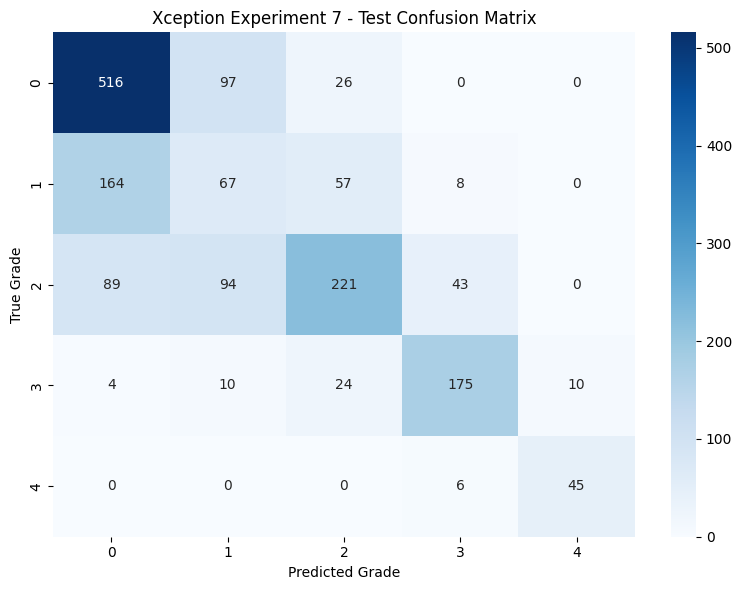

In [23]:

import torch
import timm
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Load best Experiment 7 model
model_test_exp7 = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=False,
    num_classes=5
).to(device)

model_test_exp7.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/MUFSAL_Xception_Exp7_best.pth",
        map_location=device,
        weights_only=True
    )
)

model_test_exp7.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader_exp7:
        images = images.to(device)

        outputs = model_test_exp7(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

# Calculate metrics
test_acc = accuracy_score(y_true, y_pred) * 100
test_macro_f1 = f1_score(
    y_true, y_pred,
    average="macro",
    zero_division=0
)

print("===== Experiment 7 TEST RESULTS =====")
print(f"Test Accuracy: {test_acc:.2f}%")
print(f"Macro F1: {test_macro_f1:.3f}")

print("\nClassification Report:")
print(classification_report(
    y_true, y_pred,
    target_names=test_dataset_exp7.classes,
    zero_division=0
))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=test_dataset_exp7.classes,
    yticklabels=test_dataset_exp7.classes
)

plt.xlabel("Predicted Grade")
plt.ylabel("True Grade")
plt.title("Xception Experiment 7 - Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [1]:

from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

model_path = Path(
    "/content/drive/MyDrive/MUFSAL_Xception_Exp7_best.pth"
)

print("Experiment 7 model found:", model_path.exists())

if model_path.exists():
    print("Model size:", round(model_path.stat().st_size / (1024**2), 2), "MB")


Mounted at /content/drive
Experiment 7 model found: True
Model size: 79.71 MB


In [2]:

from pathlib import Path

print("Checking test data...")

if "dataset_path" in globals():
    test_path = Path(dataset_path) / "test"
    print("Test folder found:", test_path.exists())
    print("Test path:", test_path)
else:
    print("Dataset path needs to be restored.")

print("Saved model found:", model_path.exists())


Checking test data...
Dataset path needs to be restored.
Saved model found: True


In [3]:

import os

for base in ["/content", "/content/drive/MyDrive"]:
    print("\nSearching:", base)
    for root, dirs, files in os.walk(base):
        if all(os.path.isdir(os.path.join(root, x))
               for x in ["train", "val", "test"]):
            print("Possible dataset:", root)
            dirs[:] = []
        if root.count(os.sep) - base.count(os.sep) >= 5:
            dirs[:] = []



Searching: /content

Searching: /content/drive/MyDrive


In [4]:

import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "shashwatwork/knee-osteoarthritis-dataset-with-severity"
)

print("Dataset restored:", dataset_path)
print("Folders:", os.listdir(dataset_path))


100%|██████████| 204M/204M [00:01<00:00, 156MB/s]

Extracting files...


Dataset restored: /root/.cache/kagglehub/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/versions/1
Folders: ['auto_test', 'val', 'train', 'test']


In [5]:

import cv2
import numpy as np
from PIL import Image
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Same preprocessing used for Experiment 7
class Denoise:
    def __call__(self, img):
        g = np.array(img.convert("L"))
        g = cv2.GaussianBlur(g, (3, 3), 0)
        g = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        ).apply(g)
        return Image.fromarray(g)

test_transform = transforms.Compose([
    Denoise(),
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

test_dataset = datasets.ImageFolder(
    f"{dataset_path}/test",
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("Test images:", len(test_dataset))
print("Classes:", test_dataset.classes)


Test images: 1656
Classes: ['0', '1', '2', '3', '4']


In [6]:

import torch
import timm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_exp7 = timm.create_model(
    "legacy_xception.tf_in1k",
    pretrained=False,
    num_classes=5
).to(device)

model_exp7.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/MUFSAL_Xception_Exp7_best.pth",
        map_location=device,
        weights_only=True
    )
)

model_exp7.eval()

print("Xception Experiment 7 loaded successfully!")
print("Device:", device)


Xception Experiment 7 loaded successfully!
Device: cuda


In [7]:

from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import torch

all_true = []
all_pred = []

model_exp7.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_exp7(images)
        predictions = outputs.argmax(dim=1)

        all_true.extend(labels.numpy())
        all_pred.extend(predictions.cpu().numpy())

all_true = np.array(all_true)
all_pred = np.array(all_pred)

grade1_mask = all_true == 1

print("Overall Accuracy:", round(accuracy_score(all_true, all_pred) * 100, 2), "%")
print("Macro F1:", round(f1_score(all_true, all_pred, average="macro"), 3))
print("\nGrade 1 total:", grade1_mask.sum())
print("Grade 1 correct:", np.sum(all_pred[grade1_mask] == 1))
print("Grade 1 predicted as:")
for grade in range(5):
    print(f"Grade {grade}:", np.sum(all_pred[grade1_mask] == grade))


Overall Accuracy: 61.84 %
Macro F1: 0.631

Grade 1 total: 296
Grade 1 correct: 67
Grade 1 predicted as:
Grade 0: 164
Grade 1: 67
Grade 2: 57
Grade 3: 8
Grade 4: 0


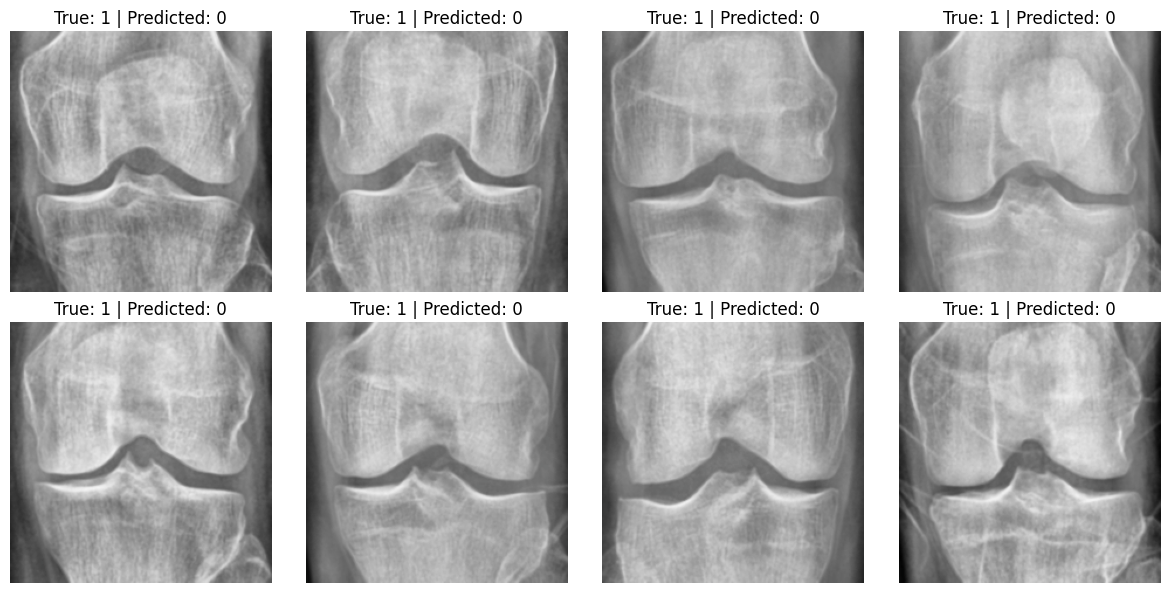

In [8]:

import matplotlib.pyplot as plt

wrong_indices = np.where(
    (all_true == 1) & (all_pred == 0)
)[0][:8]

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, idx in zip(axes.flat, wrong_indices):
    image, label = test_loader.dataset[idx]
    image = image.permute(1, 2, 0).numpy()
    image = image * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    image = np.clip(image, 0, 1)

    ax.imshow(image)
    ax.set_title("True: 1 | Predicted: 0")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [9]:

print("Test shuffle:", type(test_loader.sampler).__name__)
print("Test classes:", test_loader.dataset.classes)
print("Test images:", len(test_loader.dataset))


Test shuffle: SequentialSampler
Test classes: ['0', '1', '2', '3', '4']
Test images: 1656


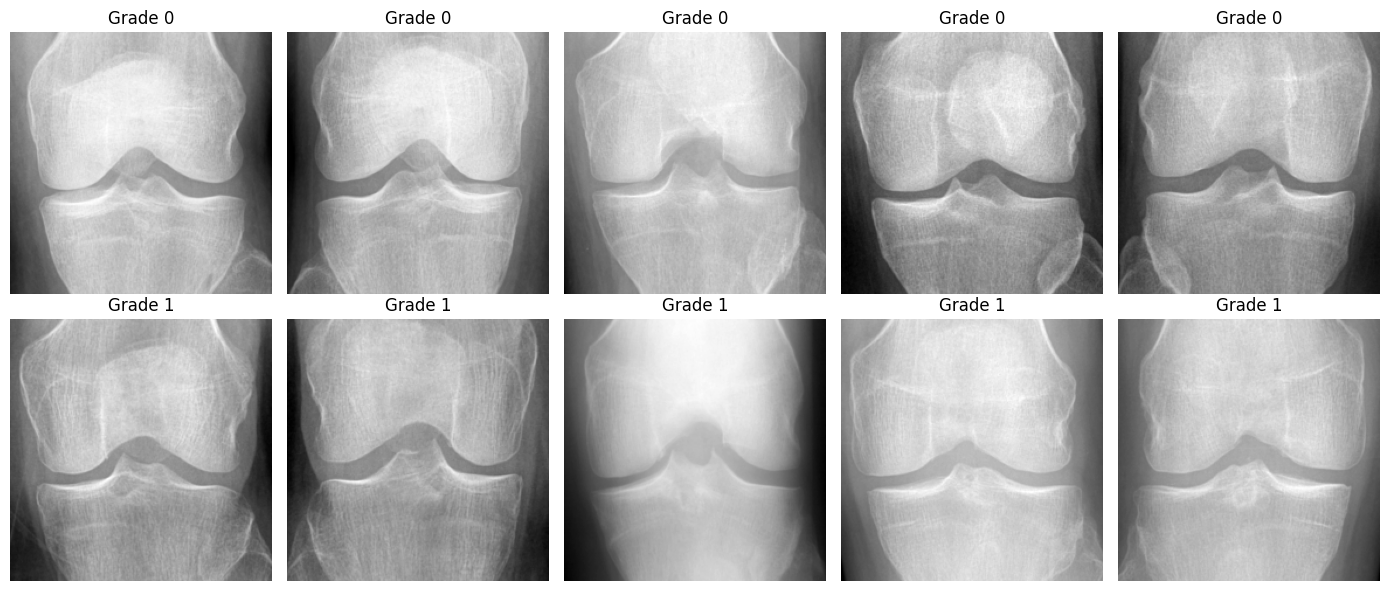

In [10]:

import matplotlib.pyplot as plt
from PIL import Image

dataset = test_loader.dataset

fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for grade in [0, 1]:
    indices = [
        i for i, (_, label) in enumerate(dataset.samples)
        if label == grade
    ][:5]

    for j, idx in enumerate(indices):
        path, _ = dataset.samples[idx]
        image = Image.open(path).convert("L")

        axes[grade, j].imshow(image, cmap="gray")
        axes[grade, j].set_title(f"Grade {grade}")
        axes[grade, j].axis("off")

plt.tight_layout()
plt.show()


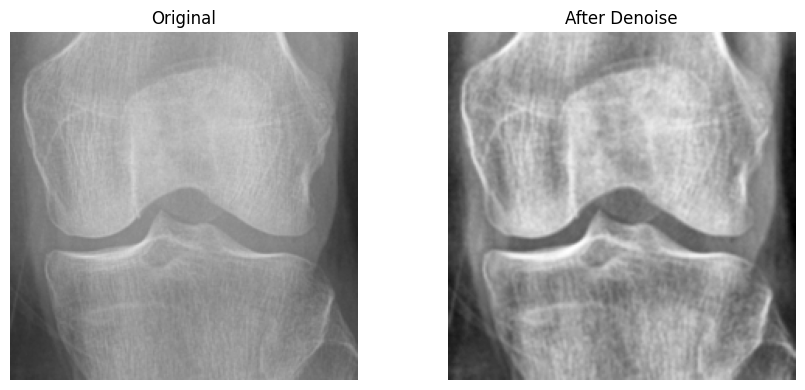

In [11]:

from PIL import Image
import matplotlib.pyplot as plt

path, _ = test_loader.dataset.samples[
    next(i for i, (_, y) in enumerate(test_loader.dataset.samples) if y == 1)
]

original = Image.open(path).convert("RGB")
processed = Denoise()(original)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(original)
axes[0].set_title("Original")

axes[1].imshow(processed, cmap="gray")
axes[1].set_title("After Denoise")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [12]:

import torch
import numpy as np
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, f1_score

# Same preprocessing, but without Denoise
test_transform_no_denoise = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# Use exactly the same test images
test_no_denoise = datasets.ImageFolder(
    test_loader.dataset.root,
    transform=test_transform_no_denoise
)

test_loader_no_denoise = DataLoader(
    test_no_denoise,
    batch_size=32,
    shuffle=False
)

y_true, y_pred = [], []

model_exp7.eval()

with torch.no_grad():
    for images, labels in test_loader_no_denoise:
        images = images.to(device)
        outputs = model_exp7(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

print("WITHOUT DENOISE")
print("Accuracy:", round(accuracy_score(y_true, y_pred) * 100, 2), "%")
print("Macro F1:", round(f1_score(y_true, y_pred, average="macro") * 100, 2), "%")
print("Grade 1 Recall:", round(
    sum((np.array(y_true) == 1) & (np.array(y_pred) == 1)) /
    sum(np.array(y_true) == 1) * 100, 2
), "%")


WITHOUT DENOISE
Accuracy: 55.07 %
Macro F1: 61.59 %
Grade 1 Recall: 43.24 %


In [13]:

import cv2
import numpy as np
from PIL import Image
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

class MildDenoise:
    def __call__(self, img):
        gray = np.array(img.convert("L"))
        gray = cv2.GaussianBlur(gray, (3, 3), 0)

        clahe = cv2.createCLAHE(
            clipLimit=1.2,
            tileGridSize=(8, 8)
        )
        result = clahe.apply(gray)
        return Image.fromarray(result)

val_transform_mild = transforms.Compose([
    MildDenoise(),
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

val_mild = datasets.ImageFolder(
    f"{dataset_path}/val",
    transform=val_transform_mild
)

val_loader_mild = DataLoader(
    val_mild,
    batch_size=32,
    shuffle=False
)

print("Validation images:", len(val_mild))
print("Classes:", val_mild.classes)


Validation images: 826
Classes: ['0', '1', '2', '3', '4']


In [14]:

from sklearn.metrics import accuracy_score, f1_score, recall_score
import torch
import numpy as np

mild_true, mild_pred = [], []

model_exp7.eval()

with torch.no_grad():
    for images, labels in val_loader_mild:
        images = images.to(device)
        outputs = model_exp7(images)
        predictions = outputs.argmax(dim=1)

        mild_true.extend(labels.numpy())
        mild_pred.extend(predictions.cpu().numpy())

mild_true = np.array(mild_true)
mild_pred = np.array(mild_pred)

print("=== MILD DENOISE - VALIDATION ===")
print("Accuracy:", round(accuracy_score(mild_true, mild_pred) * 100, 2), "%")
print("Macro F1:", round(f1_score(mild_true, mild_pred, average="macro") * 100, 2), "%")
print("Grade 1 Recall:", round(
    recall_score(mild_true, mild_pred, labels=[1], average="macro") * 100, 2
), "%")


=== MILD DENOISE - VALIDATION ===
Accuracy: 58.6 %
Macro F1: 62.07 %
Grade 1 Recall: 26.8 %


In [15]:

import os
import hashlib
from collections import defaultdict

def image_hashes(folder):
    hashes = defaultdict(list)

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith((".png", ".jpg", ".jpeg")):
                path = os.path.join(root, file)

                with open(path, "rb") as f:
                    h = hashlib.md5(f.read()).hexdigest()

                hashes[h].append(path)

    return hashes

train_hashes = image_hashes(f"{dataset_path}/train")
val_hashes = image_hashes(f"{dataset_path}/val")

duplicates = set(train_hashes) & set(val_hashes)

print("Train images:", sum(map(len, train_hashes.values())))
print("Validation images:", sum(map(len, val_hashes.values())))
print("Exact duplicates:", len(duplicates))


Train images: 5778
Validation images: 826
Exact duplicates: 0


In [16]:

from torchvision.datasets import ImageFolder
from collections import Counter

train_data = ImageFolder(f"{dataset_path}/train")
val_data = ImageFolder(f"{dataset_path}/val")

train_counts = Counter(train_data.targets)
val_counts = Counter(val_data.targets)

print("Grade | Train | Validation")
print("--------------------------")

for grade in range(5):
    print(
        f"  {grade}   | "
        f"{train_counts[grade]:4d}  | "
        f"{val_counts[grade]:4d}"
    )


Grade | Train | Validation
--------------------------
  0   | 2286  |  328
  1   | 1046  |  153
  2   | 1516  |  212
  3   |  757  |  106
  4   |  173  |   27


In [17]:

from PIL import Image
import numpy as np
from torchvision.datasets import ImageFolder

train_ds = ImageFolder(f"{dataset_path}/train")
val_ds = ImageFolder(f"{dataset_path}/val")

def dhash(path):
    with Image.open(path) as img:
        img = img.convert("L").resize((9, 8))
        pixels = np.asarray(img)
    return (pixels[:, 1:] > pixels[:, :-1]).flatten()

train_h = np.array(
    [dhash(path) for path, _ in train_ds.samples],
    dtype=np.uint8
)

val_h = np.array(
    [dhash(path) for path, _ in val_ds.samples],
    dtype=np.uint8
)

near_matches = []

for i, h in enumerate(val_h):
    distances = np.count_nonzero(train_h != h, axis=1)
    j = int(np.argmin(distances))

    if distances[j] <= 5:
        near_matches.append((i, j, int(distances[j])))

print("Possible near-duplicate pairs:", len(near_matches))
print("First matches:", near_matches[:10])


Possible near-duplicate pairs: 803
First matches: [(0, 5082, 0), (1, 729, 1), (2, 2381, 2), (3, 2048, 2), (4, 2445, 3), (5, 13, 1), (6, 2108, 4), (7, 1660, 3), (8, 4072, 1), (9, 191, 1)]


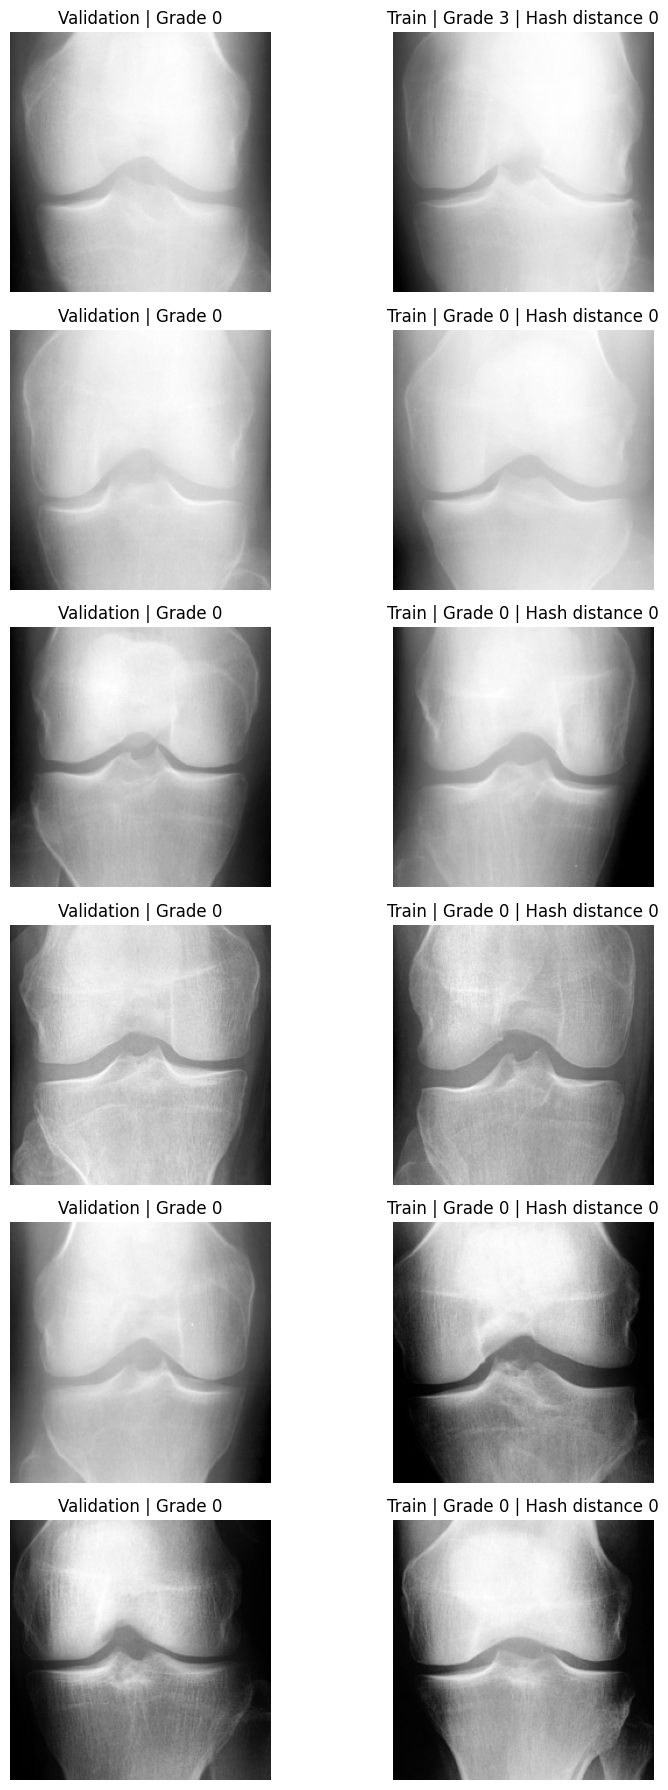

In [18]:

import matplotlib.pyplot as plt
from PIL import Image

# Show the 6 closest matches
pairs = sorted(near_matches, key=lambda x: x[2])[:6]

fig, axes = plt.subplots(len(pairs), 2, figsize=(9, 3 * len(pairs)))

for row, (val_i, train_i, distance) in enumerate(pairs):
    val_path, val_grade = val_ds.samples[val_i]
    train_path, train_grade = train_ds.samples[train_i]

    axes[row, 0].imshow(Image.open(val_path).convert("L"), cmap="gray")
    axes[row, 0].set_title(f"Validation | Grade {val_grade}")

    axes[row, 1].imshow(Image.open(train_path).convert("L"), cmap="gray")
    axes[row, 1].set_title(
        f"Train | Grade {train_grade} | Hash distance {distance}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()


In [19]:

from skimage.metrics import structural_similarity as ssim
from PIL import Image
import numpy as np

print("SSIM comparison:\n")

for val_i, train_i, distance in pairs:
    val_path, val_grade = val_ds.samples[val_i]
    train_path, train_grade = train_ds.samples[train_i]

    img1 = np.array(
        Image.open(val_path).convert("L").resize((256, 256))
    )
    img2 = np.array(
        Image.open(train_path).convert("L").resize((256, 256))
    )

    score = ssim(img1, img2, data_range=255)

    print(
        f"Val Grade {val_grade} | "
        f"Train Grade {train_grade} | "
        f"SSIM: {score:.4f}"
    )


SSIM comparison:

Val Grade 0 | Train Grade 3 | SSIM: 0.8870
Val Grade 0 | Train Grade 0 | SSIM: 0.9174
Val Grade 0 | Train Grade 0 | SSIM: 0.7509
Val Grade 0 | Train Grade 0 | SSIM: 0.6869
Val Grade 0 | Train Grade 0 | SSIM: 0.5913
Val Grade 0 | Train Grade 0 | SSIM: 0.5344


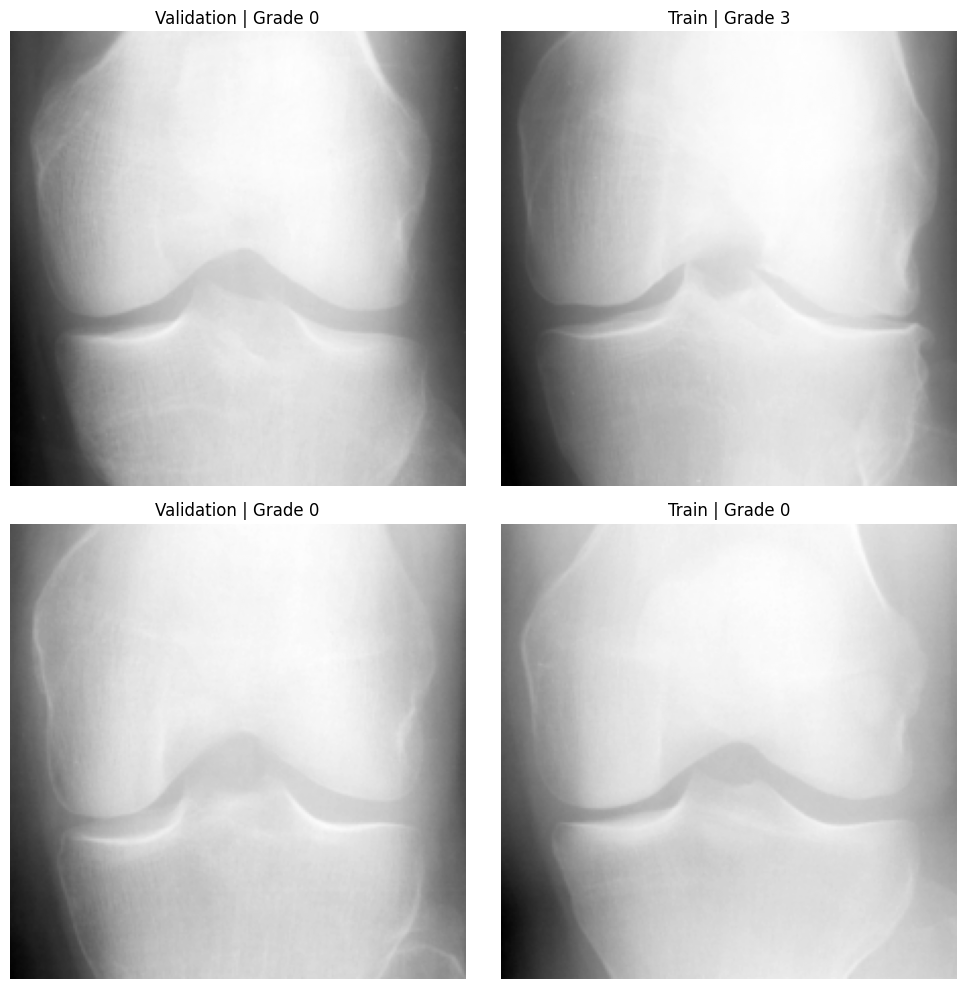

In [20]:

import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

for row, (val_i, train_i, _) in enumerate(pairs[:2]):
    val_path, val_grade = val_ds.samples[val_i]
    train_path, train_grade = train_ds.samples[train_i]

    axes[row, 0].imshow(Image.open(val_path), cmap="gray")
    axes[row, 0].set_title(f"Validation | Grade {val_grade}")

    axes[row, 1].imshow(Image.open(train_path), cmap="gray")
    axes[row, 1].set_title(f"Train | Grade {train_grade}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [21]:

import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Training: mild augmentation
train_transform_new = transforms.Compose([
    Denoise(),
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation: no augmentation
val_transform_new = transforms.Compose([
    Denoise(),
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_data_new = datasets.ImageFolder(
    f"{dataset_path}/train",
    transform=train_transform_new
)

val_data_new = datasets.ImageFolder(
    f"{dataset_path}/val",
    transform=val_transform_new
)

train_loader_new = DataLoader(
    train_data_new,
    batch_size=16,
    shuffle=True,
    num_workers=2
)

val_loader_new = DataLoader(
    val_data_new,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

print("Device:", device)
print("Train:", len(train_data_new))
print("Validation:", len(val_data_new))
print("Classes:", train_data_new.classes)


Device: cuda
Train: 5778
Validation: 826
Classes: ['0', '1', '2', '3', '4']
